<a href="https://colab.research.google.com/github/fitridianamusa/Artikel-ADW-Kelompok-8/blob/main/GARCH_LSTM_RETURN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **IMPORT LIBRARY**

In [2]:
%pip install -q arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 13.5 MB/s eta 0:00:00


In [4]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

from arch import arch_model

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

## **Membaca dan Membersihkan Data**

In [5]:
# ==========================================
# MEMBACA DATA KURS USD/IDR
# ==========================================

url = "https://raw.githubusercontent.com/fitridianamusa/Artikel-ADW-Kelompok-8/main/Data%20Historis%20USD_IDR.csv"

data = pd.read_csv(url)

print("Lima baris pertama data mentah:")
print(data.head())

print("\nNama kolom:")
print(data.columns)

print("\nUkuran data:")
print(data.shape)


# ==========================================
# MEMILIH KOLOM
# ==========================================

data = data[["Tanggal", "Terakhir"]].copy()


# ==========================================
# KONVERSI TANGGAL
# ==========================================

data["Tanggal"] = pd.to_datetime(
    data["Tanggal"],
    dayfirst=True
)


# ==========================================
# KONVERSI HARGA MENJADI NUMERIK
# ==========================================

data["Terakhir"] = (
    data["Terakhir"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .astype(float)
)


# ==========================================
# MENGURUTKAN DATA BERDASARKAN TANGGAL
# ==========================================

data = (
    data
    .sort_values(by="Tanggal")
    .reset_index(drop=True)
)


# ==========================================
# MEMERIKSA HASIL
# ==========================================

print("\nLima baris pertama setelah pembersihan:")
display(data.head())

print("\nLima baris terakhir:")
display(data.tail())

print("\nInformasi data:")
data.info()

print("\nJumlah missing value:")
print(data.isna().sum())

print("\nJumlah data:", len(data))

Lima baris pertama data mentah:
      Tanggal  Terakhir Pembukaan Tertinggi  Terendah Vol. Perubahan%
0  01/09/2026  17.715,0  17.725,0  17.735,0  17.704,5  NaN      0,00%
1  31/08/2026  17.715,0  17.750,0  17.770,0  17.712,5  NaN      0,14%
2  28/08/2026  17.690,0  17.715,0  17.722,5  17.679,0  NaN     -0,17%
3  27/08/2026  17.720,0  17.760,0  17.790,0  17.720,0  NaN      0,11%
4  26/08/2026  17.700,0  17.695,0  17.733,5  17.677,5  NaN     -0,06%

Nama kolom:
Index(['Tanggal', 'Terakhir', 'Pembukaan', 'Tertinggi', 'Terendah', 'Vol.',
       'Perubahan%'],
      dtype='object')

Ukuran data:
(1442, 7)

Lima baris pertama setelah pembersihan:


,Tanggal,Terakhir
0,2021-01-01,14213.7
1,2021-01-04,13885.0
2,2021-01-05,13900.0
3,2021-01-06,13880.0
4,2021-01-07,13890.0



Lima baris terakhir:


,Tanggal,Terakhir
1437,2026-08-26,17700.0
1438,2026-08-27,17720.0
1439,2026-08-28,17690.0
1440,2026-08-31,17715.0
1441,2026-09-01,17715.0



Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1442 entries, 0 to 1441
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Tanggal   1442 non-null   datetime64[ns]
 1   Terakhir  1442 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 22.7 KB

Jumlah missing value:
Tanggal     0
Terakhir    0
dtype: int64

Jumlah data: 1442


## **Menghitung Log Return**
Setelah data berhasil dibaca dan dibersihkan, selanjutnya menghitung log return.
$$
r_t=100\ln\left(\frac{P_t}{P_{t-1}}\right)$$

In [6]:
# ==========================================
# MENGHITUNG LOG RETURN
# ==========================================

data["Return"] = (
    100 * np.log(
        data["Terakhir"] / data["Terakhir"].shift(1)
    )
)

print("Lima baris pertama setelah menghitung return:")
display(data.head())

print("\nJumlah data harga:", len(data))
print("Jumlah return valid:", data["Return"].notna().sum())

Lima baris pertama setelah menghitung return:


,Tanggal,Terakhir,Return
0,2021-01-01,14213.7,NaN
1,2021-01-04,13885.0,-2.339717
2,2021-01-05,13900.0,0.107972
3,2021-01-06,13880.0,-0.143989
4,2021-01-07,13890.0,0.072020



Jumlah data harga: 1442
Jumlah return valid: 1441


## **Membagi Data Training dan Testing**

In [7]:
# ==========================================
# PEMBAGIAN TRAINING DAN TESTING
# ==========================================

n_train = 1400

# Data harga
train = data.iloc[:n_train].copy()
test = data.iloc[n_train:].copy()

# Data return
return_train = train["Return"].dropna().copy()
return_test = test["Return"].copy()

print("Jumlah harga training:", len(train))
print("Jumlah harga testing :", len(test))

print("Jumlah return training:", len(return_train))
print("Jumlah return testing :", len(return_test))

print("\nPeriode training:")
print(train["Tanggal"].min(), "sampai", train["Tanggal"].max())

print("\nPeriode testing:")
print(test["Tanggal"].min(), "sampai", test["Tanggal"].max())

print("\nPemeriksaan missing value pada return testing:")
print(return_test.isna().sum())

Jumlah harga training: 1400
Jumlah harga testing : 42
Jumlah return training: 1399
Jumlah return testing : 42

Periode training:
2021-01-01 00:00:00 sampai 2026-07-03 00:00:00

Periode testing:
2026-07-06 00:00:00 sampai 2026-09-01 00:00:00

Pemeriksaan missing value pada return testing:
0


## **Visualisasi Harga dan Log Return**

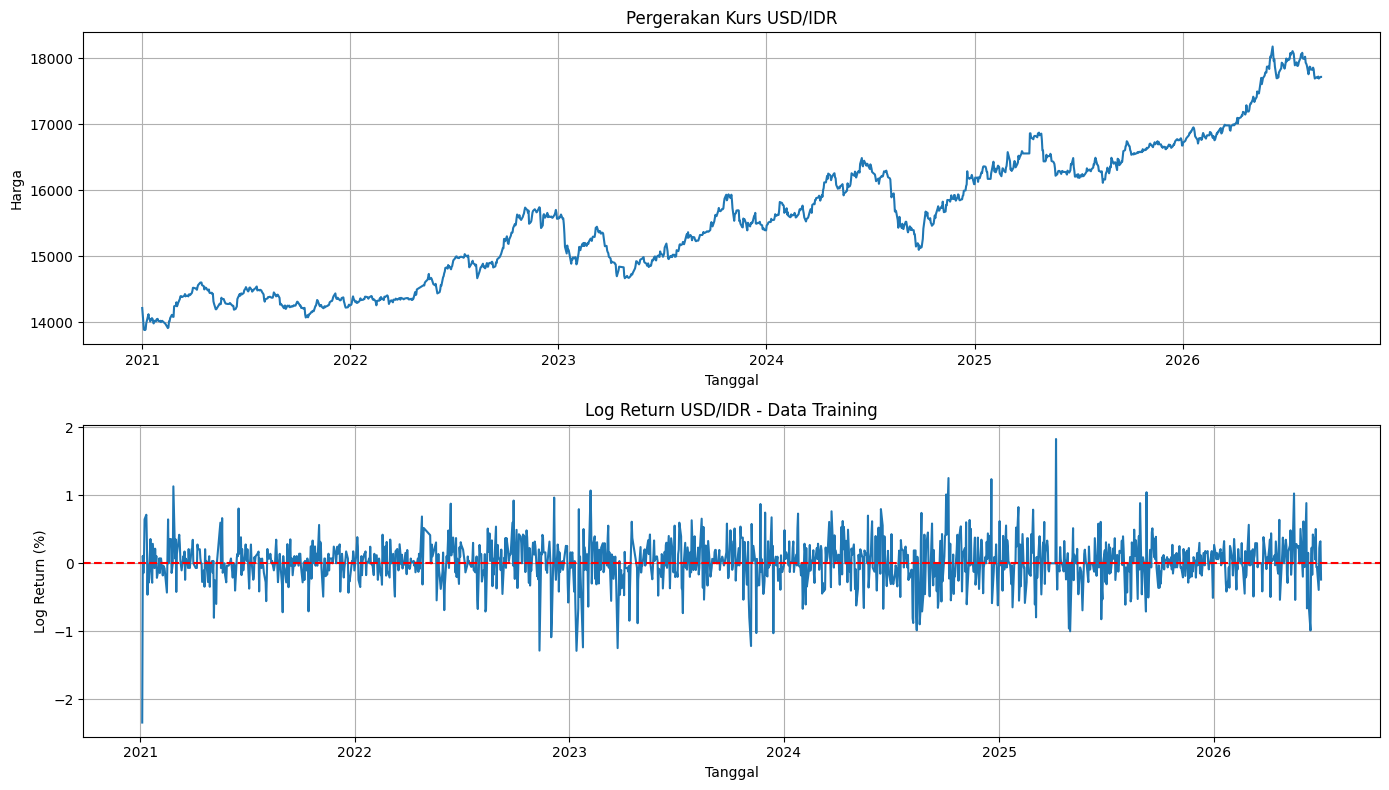

In [8]:
# ==========================================
# LANGKAH 6: VISUALISASI DATA
# ==========================================

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Grafik harga kurs
axes[0].plot(
    data["Tanggal"],
    data["Terakhir"]
)
axes[0].set_title("Pergerakan Kurs USD/IDR")
axes[0].set_xlabel("Tanggal")
axes[0].set_ylabel("Harga")
axes[0].grid(True)

# Grafik log return training
tanggal_return_train = data.loc[
    return_train.index, "Tanggal"
]

axes[1].plot(
    tanggal_return_train,
    return_train
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Log Return USD/IDR - Data Training")
axes[1].set_xlabel("Tanggal")
axes[1].set_ylabel("Log Return (%)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## **Uji Stasioneritas ADF**
Uji Augmented Dickey-Fuller (ADF) dilakukan terhadap log return training.
Hipotesis pengujian:
- $(H_0)$: log return mengandung unit root atau tidak stasioner.
- $(H_1)$: log return tidak mengandung unit root atau stasioner.

In [9]:
# ==========================================
# LANGKAH 7: UJI ADF
# ==========================================

hasil_adf = adfuller(
    return_train,
    autolag="AIC"
)

print("ADF Statistic :", hasil_adf[0])
print("p-value       :", hasil_adf[1])
print("Jumlah lag    :", hasil_adf[2])
print("Observasi     :", hasil_adf[3])

print("\nCritical Values:")
for key, value in hasil_adf[4].items():
    print(f"{key}: {value}")

if hasil_adf[1] < 0.05:
    print("\nKesimpulan: Tolak H0.")
    print("Log return stasioner pada taraf signifikansi 5%.")
else:
    print("\nKesimpulan: Gagal menolak H0.")
    print("Belum cukup bukti bahwa log return stasioner.")

ADF Statistic : -13.336523986344869
p-value       : 6.036870901333505e-25
Jumlah lag    : 6
Observasi     : 1392

Critical Values:
1%: -3.435056465447021
5%: -2.8636185648927617
10%: -2.567876622097536

Kesimpulan: Tolak H0.
Log return stasioner pada taraf signifikansi 5%.


/tmp/ipykernel_2787/1940423429.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil_adf = adfuller(


## **Plot ACF dan PACF**

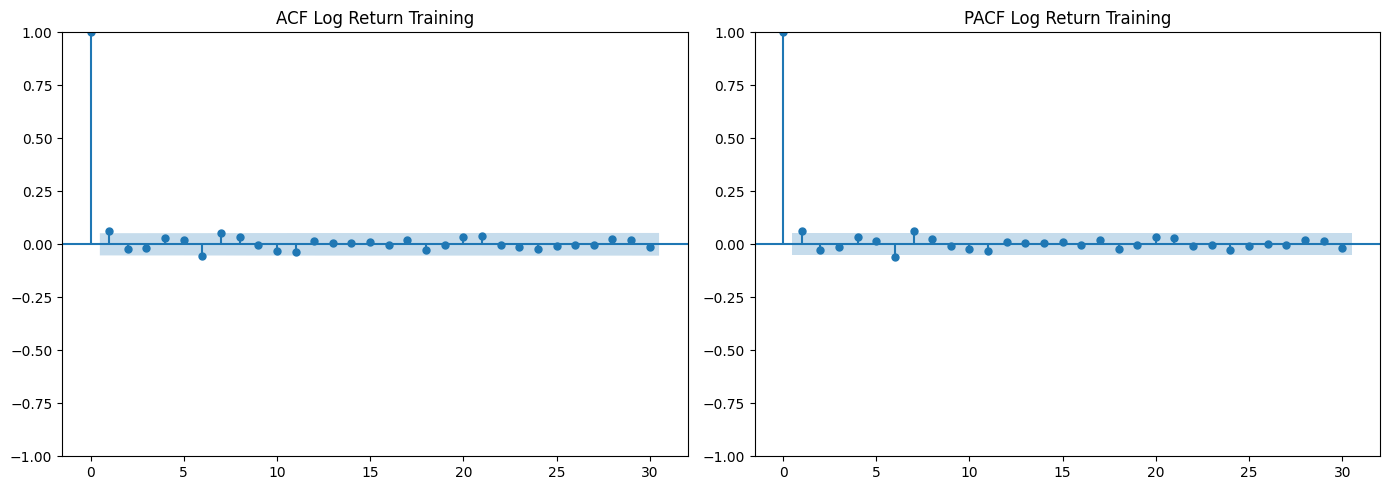

In [10]:
# ==========================================
# LANGKAH 8: PLOT ACF DAN PACF
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    return_train,
    lags=30,
    ax=axes[0]
)
axes[0].set_title("ACF Log Return Training")

plot_pacf(
    return_train,
    lags=30,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("PACF Log Return Training")

plt.tight_layout()
plt.show()

In [12]:
# ==========================================
# PEMILIHAN MODEL AR(0) - AR(7)
# ==========================================

hasil_ar = []
model_ar = {}

for p in range(8):

    # Estimasi model AR(p)
    model = ARIMA(
        return_train,
        order=(p, 0, 0),
        trend="c"
    )

    fit = model.fit()
    model_ar[p] = fit

    # Residual model
    residual = pd.Series(fit.resid).dropna()

    # Uji Ljung-Box pada lag 10 dan 20
    lb = acorr_ljungbox(
        residual,
        lags=[10, 20],
        model_df=p,
        return_df=True
    )

    hasil_ar.append({
        "Model": f"AR({p})",
        "Orde": p,
        "AIC": fit.aic,
        "BIC": fit.bic,
        "Ljung_Box_p10": lb.loc[10, "lb_pvalue"],
        "Ljung_Box_p20": lb.loc[20, "lb_pvalue"]
    })

tabel_ar = pd.DataFrame(hasil_ar)

display(
    tabel_ar.round(4).sort_values("BIC").reset_index(drop=True)
)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generate

,Model,Orde,AIC,BIC,Ljung_Box_p10,Ljung_Box_p20
0,AR(0),0,779.0734,789.5604,0.0253,0.1557
1,AR(1),1,775.6058,791.3363,0.0617,0.2762
2,AR(2),2,776.5620,797.5361,0.0665,0.3111
3,AR(3),3,778.2955,804.5130,0.0434,0.2659
4,AR(4),4,778.6837,810.1448,0.0459,0.2790
5,AR(5),5,780.3213,817.0259,0.0307,0.2577
6,AR(6),6,777.1920,819.1401,0.0997,0.5079
7,AR(7),7,772.9547,820.1463,0.6375,0.9088


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generate

,Model,Orde,AIC,BIC,Ljung_Box_p10,Ljung_Box_p20
0,AR(0),0,779.0734,789.5604,0.0253,0.1557
1,AR(1),1,775.6058,791.3363,0.0617,0.2762
2,AR(2),2,776.5620,797.5361,0.0665,0.3111
3,AR(3),3,778.2955,804.5130,0.0434,0.2659
4,AR(4),4,778.6837,810.1448,0.0459,0.2790
5,AR(5),5,780.3213,817.0259,0.0307,0.2577
6,AR(6),6,777.1920,819.1401,0.0997,0.5079
7,AR(7),7,772.9547,820.1463,0.6375,0.9088


In [13]:
# ==========================================
# UJI ARCH-LM PADA RESIDUAL AR(1)
# ==========================================

# Mengambil model AR(1)
fit_mean = model_ar[1]

# Mengambil residual
resid_ar1 = pd.Series(fit_mean.resid).dropna()

# Uji ARCH-LM dengan 10 lag
lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
    resid_ar1,
    nlags=10
)

print("Hasil Uji ARCH-LM pada Residual AR(1)")
print("------------------------------------")
print("LM Statistic :", lm_stat)
print("LM p-value   :", lm_pvalue)
print("F Statistic  :", f_stat)
print("F p-value    :", f_pvalue)

if lm_pvalue < 0.05:
    print("\nKesimpulan: Tolak H0.")
    print("Terdapat bukti efek ARCH pada residual AR(1).")
    print("Pemodelan GARCH didukung oleh hasil pengujian.")
else:
    print("\nKesimpulan: Gagal menolak H0.")
    print("Belum terdapat bukti efek ARCH yang signifikan.")
    print("Kelayakan GARCH perlu dipertimbangkan kembali.")

Hasil Uji ARCH-LM pada Residual AR(1)
------------------------------------
LM Statistic : 40.92274071271776
LM p-value   : 1.164512700978036e-05
F Statistic  : 4.183108669301255
F p-value    : 9.870977413966773e-06

Kesimpulan: Tolak H0.
Terdapat bukti efek ARCH pada residual AR(1).
Pemodelan GARCH didukung oleh hasil pengujian.


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [14]:
# ==========================================
# ESTIMASI AR(1)-GARCH(1,1)
# ==========================================

model_garch = arch_model(
    return_train,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t",
    rescale=False
)

garch_fit = model_garch.fit(
    disp="off"
)

print(garch_fit.summary())

                              AR - GARCH Model Results                              
Dep. Variable:                       Return   R-squared:                       0.002
Mean Model:                              AR   Adj. R-squared:                  0.002
Vol Model:                            GARCH   Log-Likelihood:               -245.949
Distribution:      Standardized Student's t   AIC:                           503.899
Method:                  Maximum Likelihood   BIC:                           535.356
                                              No. Observations:                 1398
Date:                      Wed, Oct 14 2026   Df Residuals:                     1396
Time:                              07:14:29   Df Model:                            2
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
C

In [15]:
# ==========================================
# PERSISTENSI VOLATILITAS
# ==========================================

params = garch_fit.params

omega = params["omega"]
alpha = params["alpha[1]"]
beta = params["beta[1]"]

persistensi = alpha + beta

print("Omega       :", omega)
print("Alpha       :", alpha)
print("Beta        :", beta)
print("Alpha + Beta:", persistensi)

if persistensi < 1:
    print(
        "\nAlpha + Beta < 1: "
        "varians bersyarat memenuhi syarat persistensi "
        "di bawah satu."
    )
else:
    print(
        "\nAlpha + Beta >= 1: "
        "perlu pemeriksaan lebih lanjut terhadap "
        "persistensi dan kestabilan varians."
    )

Omega       : 0.006187029452970508
Alpha       : 0.12813382644841098
Beta        : 0.8316550000401853
Alpha + Beta: 0.9597888264885963

Alpha + Beta < 1: varians bersyarat memenuhi syarat persistensi di bawah satu.


In [16]:
# ==========================================
# DIAGNOSTIK RESIDUAL GARCH
# ==========================================

std_resid = pd.Series(
    garch_fit.std_resid
).dropna()

# Ljung-Box pada residual terstandarisasi
lb_resid = acorr_ljungbox(
    std_resid,
    lags=[10, 20],
    model_df=1,
    return_df=True
)

# Ljung-Box pada kuadrat residual terstandarisasi
lb_squared = acorr_ljungbox(
    std_resid**2,
    lags=[10, 20],
    return_df=True
)

# ARCH-LM setelah estimasi GARCH
lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
    std_resid,
    nlags=10
)

print("Ljung-Box residual terstandarisasi:")
display(lb_resid)

print("Ljung-Box kuadrat residual terstandarisasi:")
display(lb_squared)

print("ARCH-LM setelah GARCH")
print("LM Statistic:", lm_stat)
print("LM p-value  :", lm_pvalue)
print("F Statistic :", f_stat)
print("F p-value   :", f_pvalue)

Ljung-Box residual terstandarisasi:


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,lb_stat,lb_pvalue
10,14.532428,0.104606
20,20.406561,0.370497


Ljung-Box kuadrat residual terstandarisasi:


,lb_stat,lb_pvalue
10,6.270605,0.792039
20,11.596746,0.929257


ARCH-LM setelah GARCH
LM Statistic: 6.753711575190852
LM p-value  : 0.7484735074343889
F Statistic : 0.6732949016386852
F p-value   : 0.7501081137373761


In [17]:
# ==========================================
# MEMBANDINGKAN MODEL GARCH
# ==========================================

# Model 1: Constant mean + GARCH(1,1)
garch0_fit = arch_model(
    return_train,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t",
    rescale=False
).fit(disp="off")

# Model 2: AR(1) mean + GARCH(1,1)
garch1_fit = garch_fit

# Ringkasan AIC dan BIC
hasil_garch = pd.DataFrame([
    {
        "Model": "AR(0)-GARCH(1,1)",
        "AIC": garch0_fit.aic,
        "BIC": garch0_fit.bic
    },
    {
        "Model": "AR(1)-GARCH(1,1)",
        "AIC": garch1_fit.aic,
        "BIC": garch1_fit.bic
    }
])

display(hasil_garch.round(4))

,Model,AIC,BIC
0,"AR(0)-GARCH(1,1)",517.8712,544.0888
1,"AR(1)-GARCH(1,1)",503.8989,535.3557


In [18]:
# ==========================================
# DIAGNOSTIK PERBANDINGAN MODEL GARCH
# ==========================================

def diagnostik_garch(fit, nama_model, mean_df):
    z = pd.Series(fit.std_resid).dropna()

    # Autokorelasi residual terstandarisasi
    lb_z = acorr_ljungbox(
        z,
        lags=[10, 20],
        model_df=mean_df,
        return_df=True
    )

    # Autokorelasi kuadrat residual terstandarisasi
    lb_z2 = acorr_ljungbox(
        z**2,
        lags=[10, 20],
        return_df=True
    )

    # Efek ARCH yang tersisa
    lm_stat, lm_p, f_stat, f_p = het_arch(
        z,
        nlags=10
    )

    return {
        "Model": nama_model,
        "LB_resid_p10": lb_z.loc[10, "lb_pvalue"],
        "LB_resid_p20": lb_z.loc[20, "lb_pvalue"],
        "LB_sq_p10": lb_z2.loc[10, "lb_pvalue"],
        "LB_sq_p20": lb_z2.loc[20, "lb_pvalue"],
        "ARCH_LM_p": lm_p
    }


tabel_diagnostik = pd.DataFrame([
    diagnostik_garch(
        garch0_fit,
        "AR(0)-GARCH(1,1)",
        mean_df=0
    ),
    diagnostik_garch(
        garch1_fit,
        "AR(1)-GARCH(1,1)",
        mean_df=1
    )
])

display(tabel_diagnostik.round(4))

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,Model,LB_resid_p10,LB_resid_p20,LB_sq_p10,LB_sq_p20,ARCH_LM_p
0,"AR(0)-GARCH(1,1)",0.0602,0.2674,0.8302,0.9111,0.8017
1,"AR(1)-GARCH(1,1)",0.1046,0.3705,0.7920,0.9293,0.7485


In [19]:
# ==========================================
# FORECASTING ROLLING ONE-STEP-AHEAD GARCH
# ==========================================

pred_return_garch = []
pred_vol_garch = []

# Riwayat awal hanya menggunakan data training
history_garch = return_train.astype(float).copy()

for tanggal_idx, return_aktual in return_test.items():

    # Estimasi AR(1)-GARCH(1,1) menggunakan data yang tersedia
    model = arch_model(
        history_garch,
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="t",
        rescale=False
    )

    fit = model.fit(
        disp="off",
        show_warning=False
    )

    # Prediksi return dan varians satu langkah ke depan
    forecast = fit.forecast(
        horizon=1,
        reindex=False
    )

    return_prediksi = float(
        forecast.mean.iloc[-1, 0]
    )

    volatilitas_prediksi = float(
        np.sqrt(forecast.variance.iloc[-1, 0])
    )

    pred_return_garch.append(return_prediksi)
    pred_vol_garch.append(volatilitas_prediksi)

    # Tambahkan return aktual setelah prediksi dibuat
    history_garch = pd.concat([
        history_garch,
        pd.Series(
            [float(return_aktual)],
            index=[tanggal_idx]
        )
    ])

pred_return_garch = np.array(pred_return_garch)
pred_vol_garch = np.array(pred_vol_garch)

print("Jumlah prediksi:", len(pred_return_garch))
print("\nLima prediksi return GARCH pertama:")
print(pred_return_garch[:5])

print("\nLima prediksi volatilitas pertama:")
print(pred_vol_garch[:5])

Jumlah prediksi: 42

Lima prediksi return GARCH pertama:
[0.01788742 0.03223356 0.02290318 0.02865064 0.03928083]

Lima prediksi volatilitas pertama:
[0.33588973 0.32433902 0.30827048 0.29258252 0.31718595]


In [20]:
# ==========================================
# KONVERSI RETURN KE HARGA
# ==========================================

idx_test = return_test.index.to_numpy()

# Harga aktual pada periode testing
harga_aktual = data.loc[
    idx_test, "Terakhir"
].to_numpy()

# Harga aktual satu periode sebelumnya
harga_sebelumnya = data.loc[
    idx_test - 1, "Terakhir"
].to_numpy()

# Prediksi harga berdasarkan prediksi return
harga_prediksi_garch = (
    harga_sebelumnya *
    np.exp(pred_return_garch / 100)
)

hasil_garch = pd.DataFrame({
    "Tanggal": data.loc[idx_test, "Tanggal"].to_numpy(),
    "Harga_Aktual": harga_aktual,
    "Return_Aktual": return_test.to_numpy(),
    "Return_Prediksi_GARCH": pred_return_garch,
    "Volatilitas_Prediksi": pred_vol_garch,
    "Harga_Prediksi_GARCH": harga_prediksi_garch
})

display(hasil_garch.head(10))

,Tanggal,Harga_Aktual,Return_Aktual,Return_Prediksi_GARCH,Volatilitas_Prediksi,Harga_Prediksi_GARCH
0,2026-07-06,17990.0,0.222593,0.017887,0.335890,17953.211079
1,2026-07-07,17975.0,-0.083414,0.032234,0.324339,17995.799752
2,2026-07-08,17994.0,0.105647,0.022903,0.308270,17979.117319
3,2026-07-09,18075.0,0.449140,0.028651,0.292583,17999.156134
4,2026-07-10,18050.0,-0.138408,0.039281,0.317186,18082.101406
5,2026-07-13,18105.0,0.304246,0.021557,0.306271,18053.891391
6,2026-07-14,18085.0,-0.110528,0.034534,0.307123,18111.253390
7,2026-07-15,18065.0,-0.110650,0.022602,0.295353,18089.087955
8,2026-07-16,17985.0,-0.443829,0.022434,0.284424,18069.053246
9,2026-07-17,17890.0,-0.529618,0.012373,0.318055,17987.225499


In [21]:
# ==========================================
# EVALUASI GARCH
# ==========================================

rmse_garch = np.sqrt(
    mean_squared_error(
        hasil_garch["Harga_Aktual"],
        hasil_garch["Harga_Prediksi_GARCH"]
    )
)

mae_garch = mean_absolute_error(
    hasil_garch["Harga_Aktual"],
    hasil_garch["Harga_Prediksi_GARCH"]
)

mape_garch = mean_absolute_percentage_error(
    hasil_garch["Harga_Aktual"],
    hasil_garch["Harga_Prediksi_GARCH"]
) * 100

evaluasi_garch = pd.DataFrame({
    "Model": ["AR(1)-GARCH(1,1)"],
    "RMSE": [rmse_garch],
    "MAE": [mae_garch],
    "MAPE (%)": [mape_garch]
})

display(evaluasi_garch.round(4))

,Model,RMSE,MAE,MAPE (%)
0,"AR(1)-GARCH(1,1)",50.3116,39.6725,0.2216


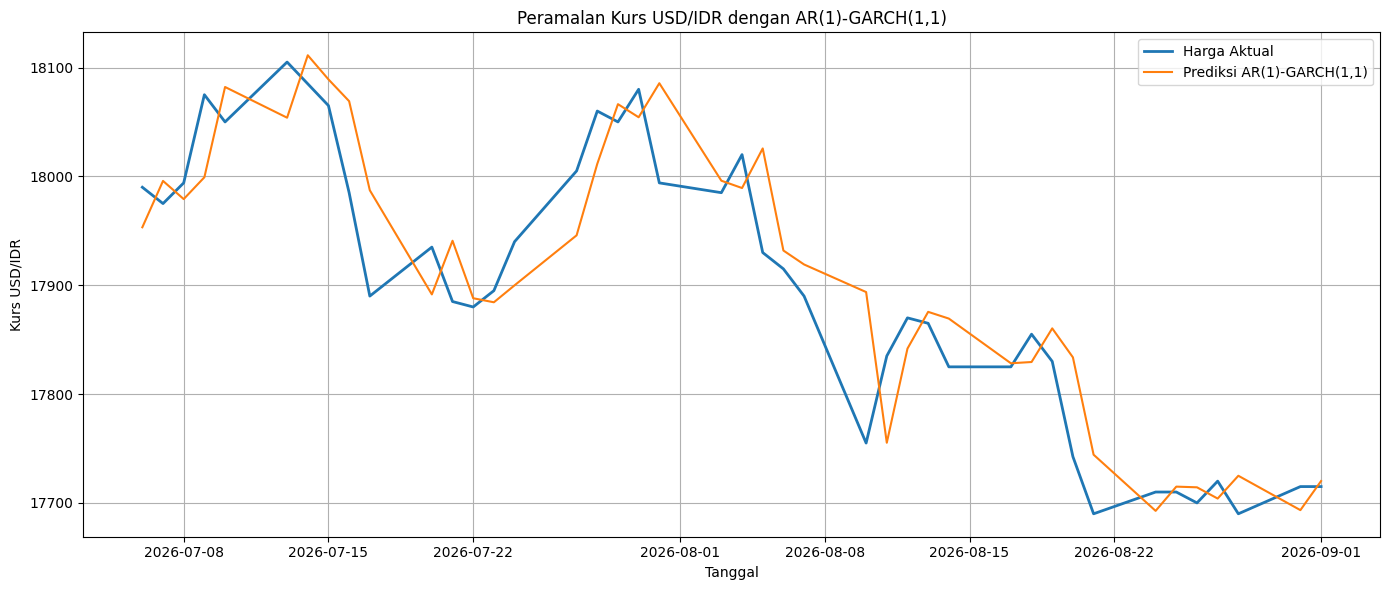

In [22]:
# ==========================================
# GRAFIK AKTUAL VS PREDIKSI
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    hasil_garch["Tanggal"],
    hasil_garch["Harga_Aktual"],
    label="Harga Aktual",
    linewidth=2
)

plt.plot(
    hasil_garch["Tanggal"],
    hasil_garch["Harga_Prediksi_GARCH"],
    label="Prediksi AR(1)-GARCH(1,1)"
)

plt.title("Peramalan Kurs USD/IDR dengan AR(1)-GARCH(1,1)")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## **LSTM**

In [23]:
# ==========================================
# LANGKAH 1: PERSIAPAN DATA LSTM
# ==========================================

lookback = 20

# Normalisasi hanya berdasarkan data training
scaler_lstm = MinMaxScaler()

r_train_scaled = scaler_lstm.fit_transform(
    return_train.to_numpy().reshape(-1, 1)
)

# Membentuk sekuens
def buat_sekuens_lstm(data_scaled, lookback):
    X, y = [], []

    for i in range(lookback, len(data_scaled)):
        X.append(data_scaled[i-lookback:i, 0])
        y.append(data_scaled[i, 0])

    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.float32)

    return X.reshape(-1, lookback, 1), y


X_train_lstm, y_train_lstm = buat_sekuens_lstm(
    r_train_scaled,
    lookback
)

print("Bentuk X training:", X_train_lstm.shape)
print("Bentuk y training:", y_train_lstm.shape)

Bentuk X training: (1379, 20, 1)
Bentuk y training: (1379,)


In [24]:
# ==========================================
# LANGKAH 2: MODEL LSTM
# ==========================================

model_lstm = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(32),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mse"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Pelatihan LSTM selesai.")

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0664 - val_loss: 0.0075
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0064 - val_loss: 0.0053
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0059 - val_loss: 0.0052
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0059 - val_loss: 0.0052
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0059 - val_loss: 0.0052
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0059 - val_loss: 0.0052
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0058 - val_loss: 0.0052
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0058 - val_loss: 0.0052
Epoch 9/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0058 - val_loss: 0.0052
Epoch 10/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0058 - val_loss: 0.0052
Epoch 11/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0058 - val_loss: 0.0052
Epoch 12/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step 

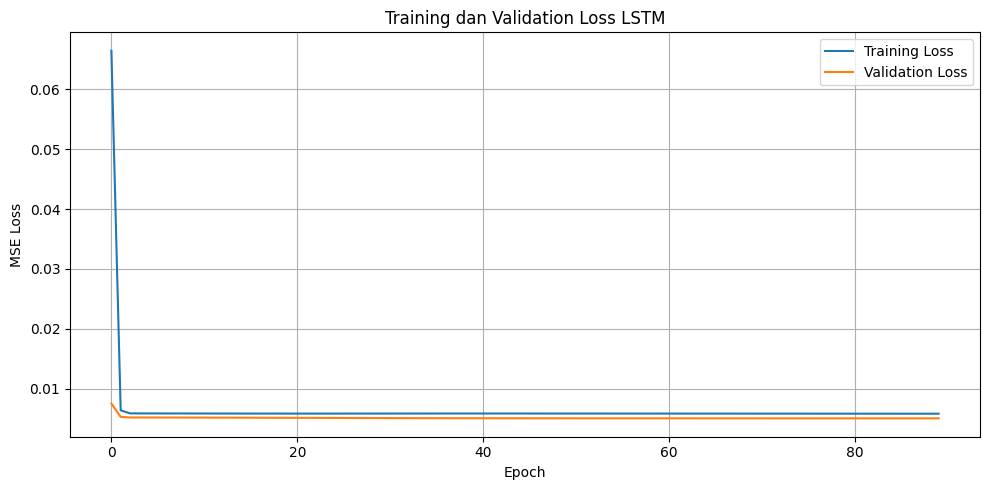

In [25]:
# ==========================================
# LANGKAH 3: GRAFIK LOSS LSTM
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training dan Validation Loss LSTM")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# LANGKAH 4: PREDIKSI RETURN LSTM
# ==========================================

pred_return_lstm = []

# Riwayat awal berisi return training yang sudah dinormalisasi
history_scaled = r_train_scaled.flatten().tolist()

for tanggal_idx, return_aktual in return_test.items():

    # Mengambil 20 return terakhir
    X_input = np.array(
        history_scaled[-lookback:],
        dtype=np.float32
    ).reshape(1, lookback, 1)

    # Prediksi return dalam skala normalisasi
    pred_scaled = model_lstm.predict(
        X_input,
        verbose=0
    )

    # Mengembalikan prediksi ke skala return asli
    pred_return = scaler_lstm.inverse_transform(
        pred_scaled
    )[0, 0]

    pred_return_lstm.append(float(pred_return))

    # Return aktual baru digunakan setelah prediksi dibuat
    aktual_scaled = scaler_lstm.transform(
        np.array([[float(return_aktual)]])
    )[0, 0]

    history_scaled.append(float(aktual_scaled))

pred_return_lstm = np.array(pred_return_lstm)

print("Jumlah prediksi return LSTM:", len(pred_return_lstm))
print("\nLima prediksi pertama:")
print(pred_return_lstm[:5])

Jumlah prediksi return LSTM: 42

Lima prediksi pertama:
[0.01680109 0.03204443 0.02263099 0.03125964 0.0521355 ]


In [27]:
# ==========================================
# LANGKAH 5: KONVERSI RETURN LSTM KE HARGA
# ==========================================

idx_test = return_test.index

tanggal_lstm = data.loc[idx_test, "Tanggal"].to_numpy()

harga_aktual_lstm = data.loc[
    idx_test, "Terakhir"
].to_numpy()

harga_sebelumnya_lstm = data.loc[
    idx_test - 1, "Terakhir"
].to_numpy()

harga_prediksi_lstm = (
    harga_sebelumnya_lstm *
    np.exp(pred_return_lstm / 100)
)

hasil_lstm = pd.DataFrame({
    "Tanggal": tanggal_lstm,
    "Harga_Aktual": harga_aktual_lstm,
    "Return_Aktual": return_test.to_numpy(),
    "Return_Prediksi_LSTM": pred_return_lstm,
    "Harga_Prediksi_LSTM": harga_prediksi_lstm
})

display(hasil_lstm.head(10))

,Tanggal,Harga_Aktual,Return_Aktual,Return_Prediksi_LSTM,Harga_Prediksi_LSTM
0,2026-07-06,17990.0,0.222593,0.016801,17953.016049
1,2026-07-07,17975.0,-0.083414,0.032044,17995.765717
2,2026-07-08,17994.0,0.105647,0.022631,17979.068380
3,2026-07-09,18075.0,0.449140,0.031260,17999.625740
4,2026-07-10,18050.0,-0.138408,0.052136,18084.425949
5,2026-07-13,18105.0,0.304246,0.031604,18055.705378
6,2026-07-14,18085.0,-0.110528,0.052210,18114.455086
7,2026-07-15,18065.0,-0.110650,0.034976,18091.326518
8,2026-07-16,17985.0,-0.443829,0.028149,18070.085888
9,2026-07-17,17890.0,-0.529618,0.003989,17985.717404


In [28]:
# ==========================================
# LANGKAH 6: PERBANDINGAN GARCH DAN LSTM
# ==========================================

def hitung_metrik(nama, aktual, prediksi):
    return {
        "Model": nama,
        "RMSE": np.sqrt(
            mean_squared_error(aktual, prediksi)
        ),
        "MAE": mean_absolute_error(
            aktual, prediksi
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            aktual, prediksi
        ) * 100
    }


tabel_perbandingan = pd.DataFrame([
    hitung_metrik(
        "AR(1)-GARCH(1,1)",
        hasil_garch["Harga_Aktual"],
        hasil_garch["Harga_Prediksi_GARCH"]
    ),
    hitung_metrik(
        "LSTM",
        hasil_lstm["Harga_Aktual"],
        hasil_lstm["Harga_Prediksi_LSTM"]
    )
])

display(
    tabel_perbandingan
    .round(4)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

,Model,RMSE,MAE,MAPE (%)
0,LSTM,50.2096,39.5906,0.2211
1,"AR(1)-GARCH(1,1)",50.3116,39.6725,0.2216


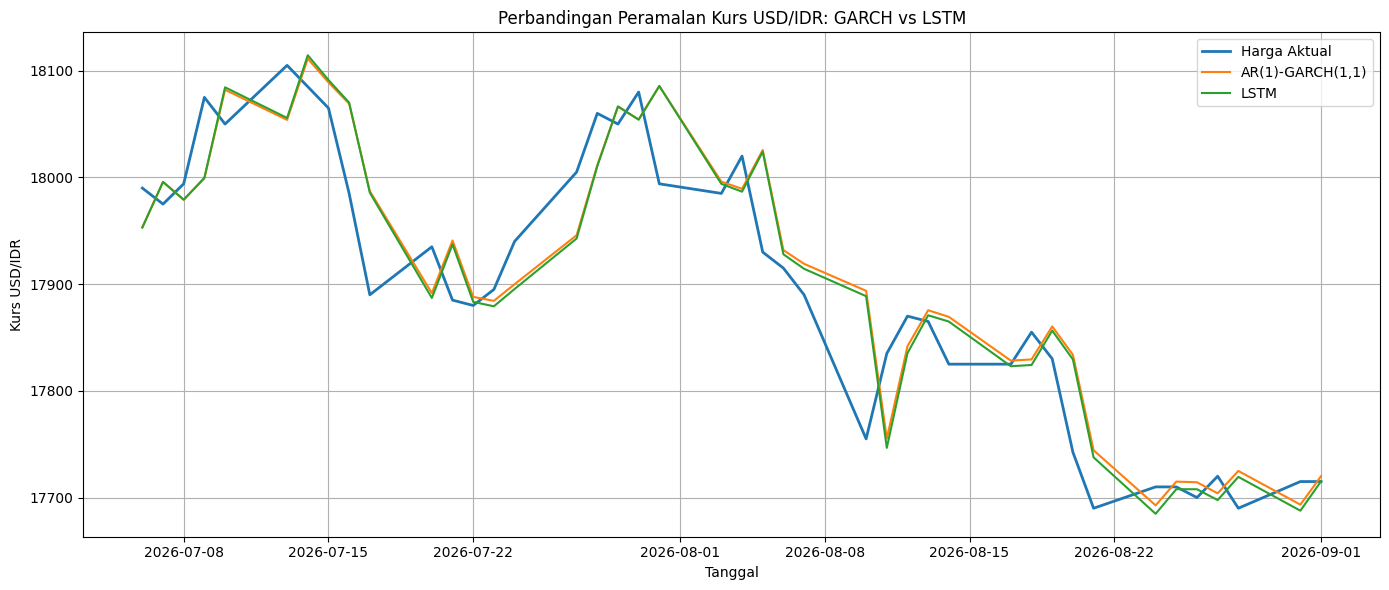

In [29]:
# ==========================================
# LANGKAH 7: GRAFIK GARCH VS LSTM
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    hasil_garch["Tanggal"],
    hasil_garch["Harga_Aktual"],
    label="Harga Aktual",
    linewidth=2
)

plt.plot(
    hasil_garch["Tanggal"],
    hasil_garch["Harga_Prediksi_GARCH"],
    label="AR(1)-GARCH(1,1)"
)

plt.plot(
    hasil_lstm["Tanggal"],
    hasil_lstm["Harga_Prediksi_LSTM"],
    label="LSTM"
)

plt.title("Perbandingan Peramalan Kurs USD/IDR: GARCH vs LSTM")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Pemeriksaan Apakah Hybrid Layak Digunakan

In [30]:
# ==========================================
# LANGKAH 1: RESIDUAL GARCH OUT-OF-SAMPLE
# ==========================================

initial_window = 700

resid_oos_values = []
resid_oos_index = []
pred_mean_oos = []

for i in range(initial_window, len(return_train)):

    # Hanya menggunakan return sebelum waktu i
    history = return_train.iloc[:i]

    # Estimasi AR(1)-GARCH(1,1)
    model = arch_model(
        history,
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="t",
        rescale=False
    )

    fit = model.fit(
        disp="off",
        show_warning=False
    )

    # Ramalan return satu langkah ke depan
    forecast = fit.forecast(
        horizon=1,
        reindex=False
    )

    pred_return = float(
        forecast.mean.iloc[-1, 0]
    )

    # Return aktual pada waktu i
    return_aktual = float(return_train.iloc[i])

    # Error ramalan GARCH
    resid = return_aktual - pred_return

    pred_mean_oos.append(pred_return)
    resid_oos_values.append(resid)
    resid_oos_index.append(return_train.index[i])

resid_train_oos = pd.Series(
    resid_oos_values,
    index=resid_oos_index,
    name="Residual_GARCH_OOS"
)

print("Jumlah residual OOS:", len(resid_train_oos))
display(resid_train_oos.head())
display(resid_train_oos.describe())

Jumlah residual OOS: 699


,Residual_GARCH_OOS
701,-0.038966
702,0.290712
703,-0.547417
704,-0.789177
705,-1.193527


,Residual_GARCH_OOS
count,699.000000
mean,-0.006607
std,0.335796
min,-1.193527
25%,-0.166003
50%,-0.019024
75%,0.179367
max,1.802256


In [31]:
# ==========================================
# LANGKAH 2: DIAGNOSTIK RESIDUAL OOS
# ==========================================

# 1. Uji Ljung-Box pada residual
lb_resid_oos = acorr_ljungbox(
    resid_train_oos,
    lags=[10, 20],
    return_df=True
)

# 2. Uji Ljung-Box pada kuadrat residual
lb_squared_oos = acorr_ljungbox(
    resid_train_oos**2,
    lags=[10, 20],
    return_df=True
)

# 3. Uji ARCH-LM
lm_stat_oos, lm_pvalue_oos, f_stat_oos, f_pvalue_oos = (
    het_arch(
        resid_train_oos,
        nlags=10
    )
)

print("Ljung-Box residual GARCH OOS:")
display(lb_resid_oos)

print("Ljung-Box kuadrat residual GARCH OOS:")
display(lb_squared_oos)

print("\nARCH-LM residual GARCH OOS")
print("LM Statistic:", lm_stat_oos)
print("LM p-value  :", lm_pvalue_oos)
print("F Statistic :", f_stat_oos)
print("F p-value   :", f_pvalue_oos)

Ljung-Box residual GARCH OOS:


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,lb_stat,lb_pvalue
10,10.593040,0.390090
20,20.369221,0.435056


Ljung-Box kuadrat residual GARCH OOS:


,lb_stat,lb_pvalue
10,16.063298,0.097835
20,30.973647,0.055539



ARCH-LM residual GARCH OOS
LM Statistic: 12.690717497900085
LM p-value  : 0.24148183931101203
F Statistic : 1.2722443246296204
F p-value   : 0.24219558294175542


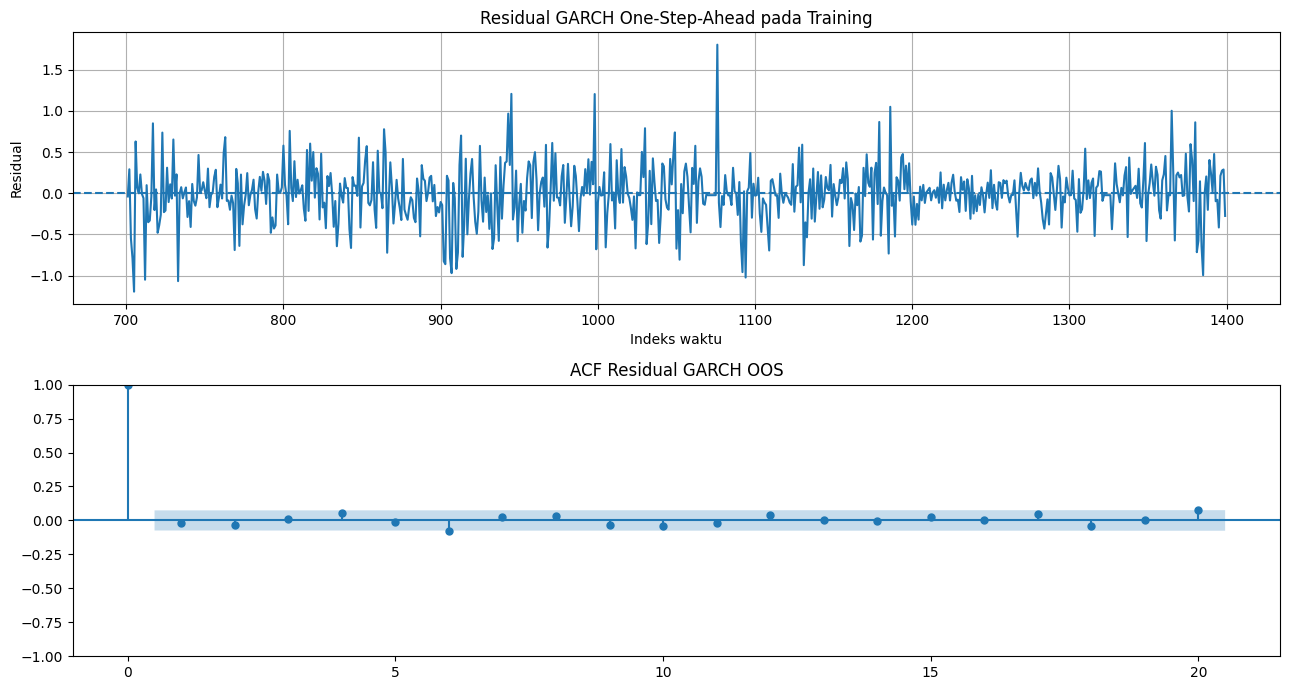

In [32]:
# ==========================================
# LANGKAH 3: PLOT RESIDUAL OOS DAN ACF
# ==========================================

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

axes[0].plot(
    resid_train_oos.index,
    resid_train_oos
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residual GARCH One-Step-Ahead pada Training")
axes[0].set_xlabel("Indeks waktu")
axes[0].set_ylabel("Residual")
axes[0].grid(True)

plot_acf(
    resid_train_oos,
    lags=20,
    ax=axes[1]
)
axes[1].set_title("ACF Residual GARCH OOS")

plt.tight_layout()
plt.show()

BDS test (Brock–Dechert–Scheinkman test) adalah uji statistik untuk memeriksa apakah suatu deret data bersifat independent and identically distributed (i.i.d.), yaitu setiap observasi saling independen dan berasal dari distribusi probabilitas yang sama.

Hipotesis yang diuji adalah:
- $H_0$: residual bersifat i.i.d. atau tidak menunjukkan ketergantungan yang bertentangan dengan asumsi independensi dan distribusi identik.
- $H_1$: residual tidak bersifat i.i.d., sehingga terdapat indikasi ketergantungan atau struktur yang belum terjelaskan.

Taraf signifikansi yang digunakan adalah $alpha=0{,}05$.


In [33]:
# ==========================================
# LANGKAH 4: BDS TEST RESIDUAL GARCH OOS
# ==========================================

from statsmodels.tsa.stattools import bds

resid_bds = resid_train_oos.dropna().to_numpy()

bds_stat, bds_pvalue = bds(
    resid_bds,
    max_dim=5
)

bds_stat = np.atleast_1d(bds_stat)
bds_pvalue = np.atleast_1d(bds_pvalue)

tabel_bds = pd.DataFrame({
    "Dimensi": np.arange(2, 2 + len(bds_stat)),
    "BDS_Statistic": bds_stat,
    "p_value": bds_pvalue
})

display(tabel_bds.round(5))

,Dimensi,BDS_Statistic,p_value
0,2,4.01555,0.00006
1,3,4.41397,0.00001
2,4,4.94559,0.00000
3,5,5.15077,0.00000


Seluruh p-value lebih kecil dari 0,05. Dengan demikian, hipotesis nol ditolak pada semua dimensi yang diuji.

Kesimpulannya: terdapat bukti statistik bahwa residual peramalan GARCH belum bersifat i.i.d.

## **HYBRID GARCH-LSTM**

In [34]:
# ==========================================
# LANGKAH 1: PERSIAPAN RESIDUAL LSTM
# ==========================================

from sklearn.preprocessing import MinMaxScaler

# Urutkan residual berdasarkan waktu
resid_train_oos = resid_train_oos.sort_index()

# Pembagian kronologis 80% training dan 20% validasi
split_resid = int(len(resid_train_oos) * 0.8)

resid_train_part = resid_train_oos.iloc[:split_resid]
resid_val_part = resid_train_oos.iloc[split_resid:]

print("Jumlah residual untuk pelatihan:", len(resid_train_part))
print("Jumlah residual untuk validasi:", len(resid_val_part))

# Normalisasi hanya menggunakan residual bagian training
scaler_resid = MinMaxScaler()

resid_scaled = scaler_resid.fit_transform(
    resid_train_part.to_numpy().reshape(-1, 1)
)

# Membuat sekuens
X_resid_train, y_resid_train = buat_sekuens_lstm(
    resid_scaled,
    lookback
)

print("Bentuk X:", X_resid_train.shape)
print("Bentuk y:", y_resid_train.shape)

Jumlah residual untuk pelatihan: 559
Jumlah residual untuk validasi: 140
Bentuk X: (539, 20, 1)
Bentuk y: (539,)


Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0263 - val_loss: 0.0031
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0159 - val_loss: 0.0025
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0150 - val_loss: 0.0026
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0148 - val_loss: 0.0025
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0147 - val_loss: 0.0025
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0147 - val_loss: 0.0025
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0147 - val_loss: 0.0025
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0146 - val_loss: 0.0025
Epoch 9/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0146 - val_loss: 0.0025
Epoch 10/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0146 - val_loss: 0.0025
Epoch 11/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0146 - val_loss: 0.0025
Epoch 12/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

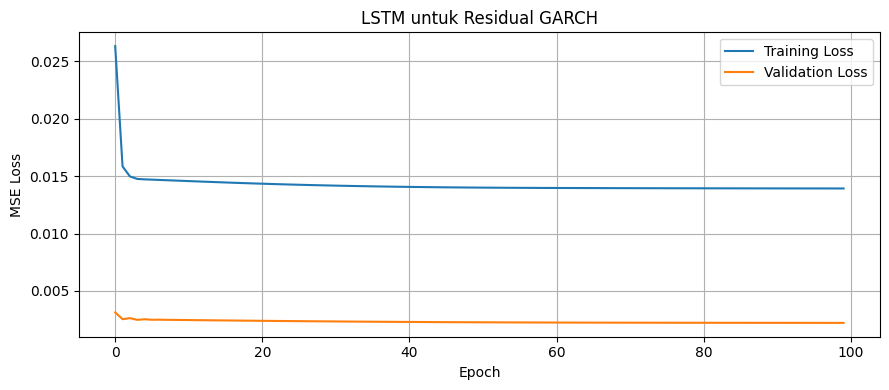

In [35]:
# ==========================================
# LANGKAH 2: MODEL LSTM RESIDUAL
# ==========================================

model_resid_val = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(16),
    Dense(1)
])

model_resid_val.compile(
    optimizer="adam",
    loss="mse"
)

early_stop_resid = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_resid = model_resid_val.fit(
    X_resid_train,
    y_resid_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_resid],
    verbose=1
)

# Grafik loss
plt.figure(figsize=(9, 4))

plt.plot(
    history_resid.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_resid.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM untuk Residual GARCH")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
# ==========================================
# LANGKAH 3: PREDIKSI RESIDUAL VALIDASI
# ==========================================

# Riwayat awal hanya dari residual training
history_resid_scaled = resid_scaled.flatten().tolist()

pred_resid_val = []

for resid_aktual in resid_val_part:

    X_input = np.array(
        history_resid_scaled[-lookback:],
        dtype=np.float32
    ).reshape(1, lookback, 1)

    pred_scaled = model_resid_val.predict(
        X_input,
        verbose=0
    )

    pred_resid = scaler_resid.inverse_transform(
        pred_scaled
    )[0, 0]

    pred_resid_val.append(float(pred_resid))

    # Residual aktual baru dimasukkan setelah prediksi
    aktual_scaled = scaler_resid.transform(
        np.array([[float(resid_aktual)]])
    )[0, 0]

    history_resid_scaled.append(float(aktual_scaled))

pred_resid_val = np.array(pred_resid_val)

print("Jumlah prediksi residual validasi:", len(pred_resid_val))

Jumlah prediksi residual validasi: 140


In [37]:
# ==========================================
# MEMILIH ALPHA BERDASARKAN RMSE HARGA
# ==========================================

# Prediksi GARCH OOS yang tersimpan pada langkah sebelumnya
pred_return_train_oos = pd.Series(
    pred_mean_oos,
    index=resid_train_oos.index
)

idx_val = resid_val_part.index

pred_garch_val = pred_return_train_oos.loc[
    idx_val
].to_numpy()

harga_prev_val = data.loc[
    idx_val - 1, "Terakhir"
].to_numpy()

harga_actual_val = data.loc[
    idx_val, "Terakhir"
].to_numpy()

daftar_alpha = [0, 0.1, 0.25, 0.5, 0.75, 1.0]

hasil_alpha = []

for alpha in daftar_alpha:

    pred_return_val = (
        pred_garch_val +
        alpha * pred_resid_val
    )

    pred_harga_val = (
        harga_prev_val *
        np.exp(pred_return_val / 100)
    )

    rmse_val = np.sqrt(
        mean_squared_error(
            harga_actual_val,
            pred_harga_val
        )
    )

    hasil_alpha.append({
        "Alpha": alpha,
        "RMSE_Harga_Validasi": rmse_val
    })

tabel_alpha = pd.DataFrame(hasil_alpha)

display(tabel_alpha.round(5))

best_alpha = float(
    tabel_alpha.loc[
        tabel_alpha["RMSE_Harga_Validasi"].idxmin(),
        "Alpha"
    ]
)

print("Alpha terpilih berdasarkan validasi:", best_alpha)

,Alpha,RMSE_Harga_Validasi
0,0.00,50.93632
1,0.10,50.94668
2,0.25,50.96351
3,0.50,50.99497
4,0.75,51.03070
5,1.00,51.07067


Alpha terpilih berdasarkan validasi: 0.0


In [38]:
# ==========================================
# LANGKAH 4: LATIH ULANG LSTM RESIDUAL
# ==========================================

scaler_resid_full = MinMaxScaler()

resid_full_scaled = scaler_resid_full.fit_transform(
    resid_train_oos.to_numpy().reshape(-1, 1)
)

X_resid_full, y_resid_full = buat_sekuens_lstm(
    resid_full_scaled,
    lookback
)

model_resid_full = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(16),
    Dense(1)
])

model_resid_full.compile(
    optimizer="adam",
    loss="mse"
)

early_stop_full = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

model_resid_full.fit(
    X_resid_full,
    y_resid_full,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_full],
    verbose=1
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - loss: 0.0807 - val_loss: 0.0179
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0145 - val_loss: 0.0149
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0124 - val_loss: 0.0151
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0122 - val_loss: 0.0146
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0122 - val_loss: 0.0147
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0122 - val_loss: 0.0146
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0122 - val_loss: 0.0147
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0121 - val_loss: 0.0146
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0121 - val_loss: 0.0146
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0121 - val_loss: 0.0146
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0121 - val_loss: 0.0146
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - lo

In [39]:
# ==========================================
# PREDIKSI HYBRID PADA DATA TESTING
# ==========================================

history_resid_test = resid_full_scaled.flatten().tolist()

pred_resid_test = []

for return_aktual, pred_garch in zip(
    return_test.to_numpy(),
    pred_return_garch
):

    X_input = np.array(
        history_resid_test[-lookback:],
        dtype=np.float32
    ).reshape(1, lookback, 1)

    pred_scaled = model_resid_full.predict(
        X_input,
        verbose=0
    )

    pred_resid = scaler_resid_full.inverse_transform(
        pred_scaled
    )[0, 0]

    pred_resid_test.append(float(pred_resid))

    # Error GARCH aktual baru diketahui setelah prediksi dibuat
    resid_aktual = float(return_aktual - pred_garch)

    resid_actual_scaled = scaler_resid_full.transform(
        np.array([[resid_aktual]])
    )[0, 0]

    history_resid_test.append(float(resid_actual_scaled))

pred_resid_test = np.array(pred_resid_test)

# Prediksi return hybrid
pred_return_hybrid = (
    pred_return_garch +
    best_alpha * pred_resid_test
)

# Konversi ke harga
harga_prev_test = data.loc[
    return_test.index - 1, "Terakhir"
].to_numpy()

harga_pred_hybrid = (
    harga_prev_test *
    np.exp(pred_return_hybrid / 100)
)

print("Jumlah prediksi hybrid:", len(harga_pred_hybrid))
print("Alpha yang digunakan:", best_alpha)

Jumlah prediksi hybrid: 42
Alpha yang digunakan: 0.0


In [40]:
# ==========================================
# EVALUASI AKHIR GARCH, LSTM DAN HYBRID
# ==========================================

harga_aktual_test = data.loc[
    return_test.index, "Terakhir"
].to_numpy()

tabel_akhir = pd.DataFrame([
    hitung_metrik(
        "AR(1)-GARCH(1,1)",
        harga_aktual_test,
        harga_prediksi_garch
    ),
    hitung_metrik(
        "LSTM",
        harga_aktual_test,
        harga_prediksi_lstm
    ),
    hitung_metrik(
        "Hybrid GARCH-LSTM",
        harga_aktual_test,
        harga_pred_hybrid
    )
])

display(
    tabel_akhir
    .round(5)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

,Model,RMSE,MAE,MAPE (%)
0,LSTM,50.20958,39.59059,0.22109
1,"AR(1)-GARCH(1,1)",50.31160,39.67248,0.22159
2,Hybrid GARCH-LSTM,50.31160,39.67248,0.22159


In [41]:
# Periksa bobot koreksi yang terpilih
print("Alpha terpilih:", best_alpha)

# Bandingkan prediksi return
print(
    "Selisih maksimum prediksi return:",
    np.max(np.abs(pred_return_hybrid - pred_return_garch))
)

# Bandingkan prediksi harga
print(
    "Selisih maksimum prediksi harga:",
    np.max(np.abs(harga_pred_hybrid - harga_prediksi_garch))
)

# Tampilkan hasil pemilihan alpha pada validasi
display(tabel_alpha)

Alpha terpilih: 0.0
Selisih maksimum prediksi return: 0.0
Selisih maksimum prediksi harga: 0.0


,Alpha,RMSE_Harga_Validasi
0,0.00,50.936315
1,0.10,50.946680
2,0.25,50.963510
3,0.50,50.994974
4,0.75,51.030698
5,1.00,51.070673


In [42]:
# ==========================================
# HYBRID GARCH-LSTM DENGAN ALPHA = 1
# ==========================================

alpha_uji = 1.0

# Prediksi return hybrid
pred_return_hybrid_a1 = (
    pred_return_garch +
    alpha_uji * pred_resid_test
)

# Konversi return menjadi harga
harga_pred_hybrid_a1 = (
    harga_prev_test *
    np.exp(pred_return_hybrid_a1 / 100)
)

print("Alpha yang digunakan:", alpha_uji)
print("Lima prediksi harga hybrid pertama:")
print(harga_pred_hybrid_a1[:5])

Alpha yang digunakan: 1.0
Lima prediksi harga hybrid pertama:
[17952.86778547 17994.81114584 17979.03300736 17999.30062897
 18081.6970466 ]


In [43]:
# ==========================================
# EVALUASI HYBRID ALPHA = 1
# ==========================================

tabel_alpha1 = pd.DataFrame([
    hitung_metrik(
        "AR(1)-GARCH(1,1)",
        harga_aktual_test,
        harga_prediksi_garch
    ),
    hitung_metrik(
        "LSTM",
        harga_aktual_test,
        harga_prediksi_lstm
    ),
    hitung_metrik(
        "Hybrid GARCH-LSTM (alpha=1)",
        harga_aktual_test,
        harga_pred_hybrid_a1
    )
])

display(
    tabel_alpha1
    .round(5)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

,Model,RMSE,MAE,MAPE (%)
0,LSTM,50.20958,39.59059,0.22109
1,"AR(1)-GARCH(1,1)",50.31160,39.67248,0.22159
2,Hybrid GARCH-LSTM (alpha=1),50.32577,39.52429,0.22074


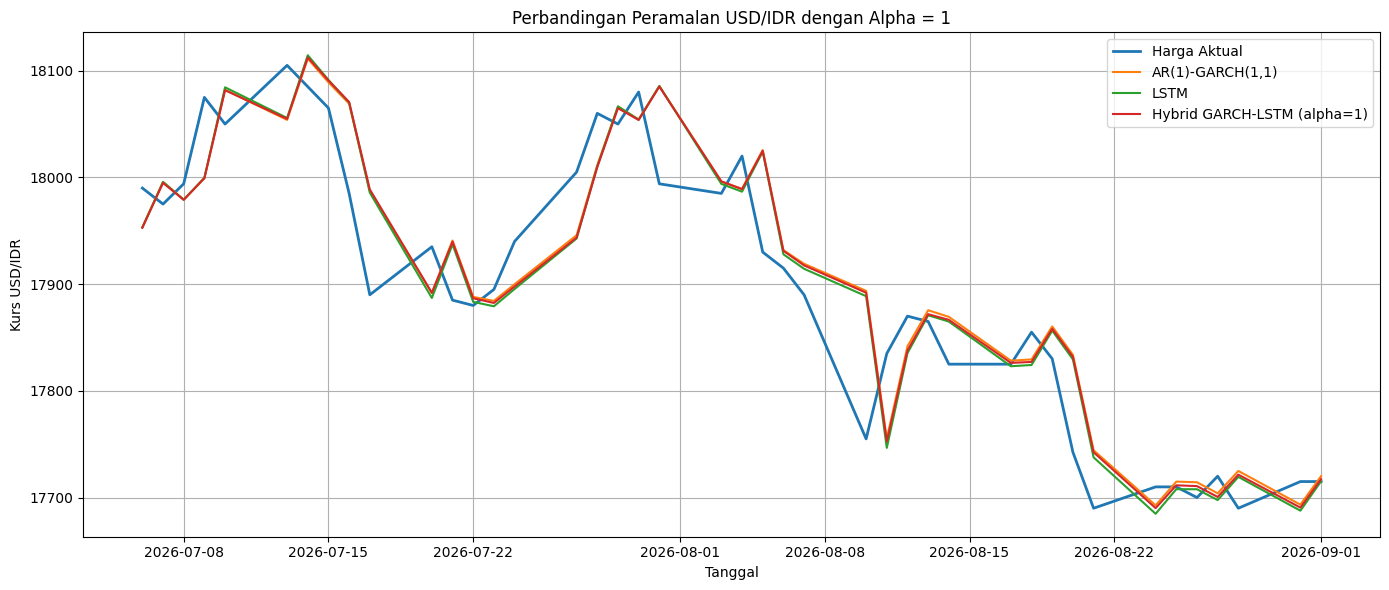

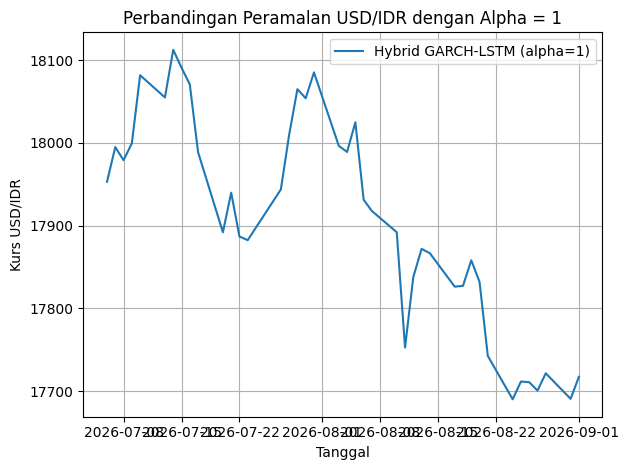

In [45]:
# ==========================================
# GRAFIK PERBANDINGAN ALPHA = 1
# ==========================================

# Mendefinisikan tanggal data testing
tanggal_test = data.loc[
    return_test.index, "Tanggal"
].to_numpy()

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_test,
    harga_aktual_test,
    label="Harga Aktual",
    linewidth=2
)

plt.plot(
    tanggal_test,
    harga_prediksi_garch,
    label="AR(1)-GARCH(1,1)"
)

plt.plot(
    tanggal_test,
    harga_prediksi_lstm,
    label="LSTM"
)

plt.plot(
    tanggal_test,
    harga_pred_hybrid_a1,
    label="Hybrid GARCH-LSTM (alpha=1)"
)

plt.title("Perbandingan Peramalan USD/IDR dengan Alpha = 1")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.plot(
    tanggal_test,
    harga_pred_hybrid_a1,
    label="Hybrid GARCH-LSTM (alpha=1)"
)

plt.title("Perbandingan Peramalan USD/IDR dengan Alpha = 1")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [46]:
# ==========================================
# EVALUASI GARCH, LSTM, DAN HYBRID (ALPHA = 1)
# ==========================================

def evaluasi_model(nama_model, aktual, prediksi):
    aktual = np.asarray(aktual).ravel()
    prediksi = np.asarray(prediksi).ravel()

    if len(aktual) != len(prediksi):
        raise ValueError(
            f"Jumlah data aktual dan prediksi tidak sama: {nama_model}"
        )

    return {
        "Model": nama_model,
        "RMSE": np.sqrt(
            mean_squared_error(aktual, prediksi)
        ),
        "MAE": mean_absolute_error(
            aktual, prediksi
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            aktual, prediksi
        ) * 100
    }


# Harga aktual testing
aktual_test = np.asarray(harga_aktual_test).ravel()

# Evaluasi ketiga model
hasil_evaluasi_alpha1 = pd.DataFrame([
    evaluasi_model(
        "AR(1)-GARCH(1,1)",
        aktual_test,
        harga_prediksi_garch
    ),
    evaluasi_model(
        "LSTM",
        aktual_test,
        harga_prediksi_lstm
    ),
    evaluasi_model(
        "Hybrid GARCH-LSTM (alpha=1)",
        aktual_test,
        harga_pred_hybrid_a1
    )
])

display(
    hasil_evaluasi_alpha1
    .round(5)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

,Model,RMSE,MAE,MAPE (%)
0,LSTM,50.20958,39.59059,0.22109
1,"AR(1)-GARCH(1,1)",50.31160,39.67248,0.22159
2,Hybrid GARCH-LSTM (alpha=1),50.32577,39.52429,0.22074


In [47]:
# ==========================================
# PERUBAHAN AKURASI HYBRID TERHADAP GARCH
# ==========================================

hasil_garch = hasil_evaluasi_alpha1.loc[
    hasil_evaluasi_alpha1["Model"] == "AR(1)-GARCH(1,1)"
].iloc[0]

hasil_hybrid = hasil_evaluasi_alpha1.loc[
    hasil_evaluasi_alpha1["Model"] == "Hybrid GARCH-LSTM (alpha=1)"
].iloc[0]

perubahan_rmse = (
    (hasil_garch["RMSE"] - hasil_hybrid["RMSE"])
    / hasil_garch["RMSE"] * 100
)

perubahan_mae = (
    (hasil_garch["MAE"] - hasil_hybrid["MAE"])
    / hasil_garch["MAE"] * 100
)

print(f"Perubahan RMSE hybrid terhadap GARCH: {perubahan_rmse:.5f}%")
print(f"Perubahan MAE hybrid terhadap GARCH : {perubahan_mae:.5f}%")

if perubahan_rmse > 0:
    print("RMSE hybrid lebih rendah daripada GARCH.")
elif perubahan_rmse < 0:
    print("RMSE hybrid lebih tinggi daripada GARCH.")
else:
    print("RMSE hybrid sama dengan GARCH.")

Perubahan RMSE hybrid terhadap GARCH: -0.02817%
Perubahan MAE hybrid terhadap GARCH : 0.37352%
RMSE hybrid lebih tinggi daripada GARCH.


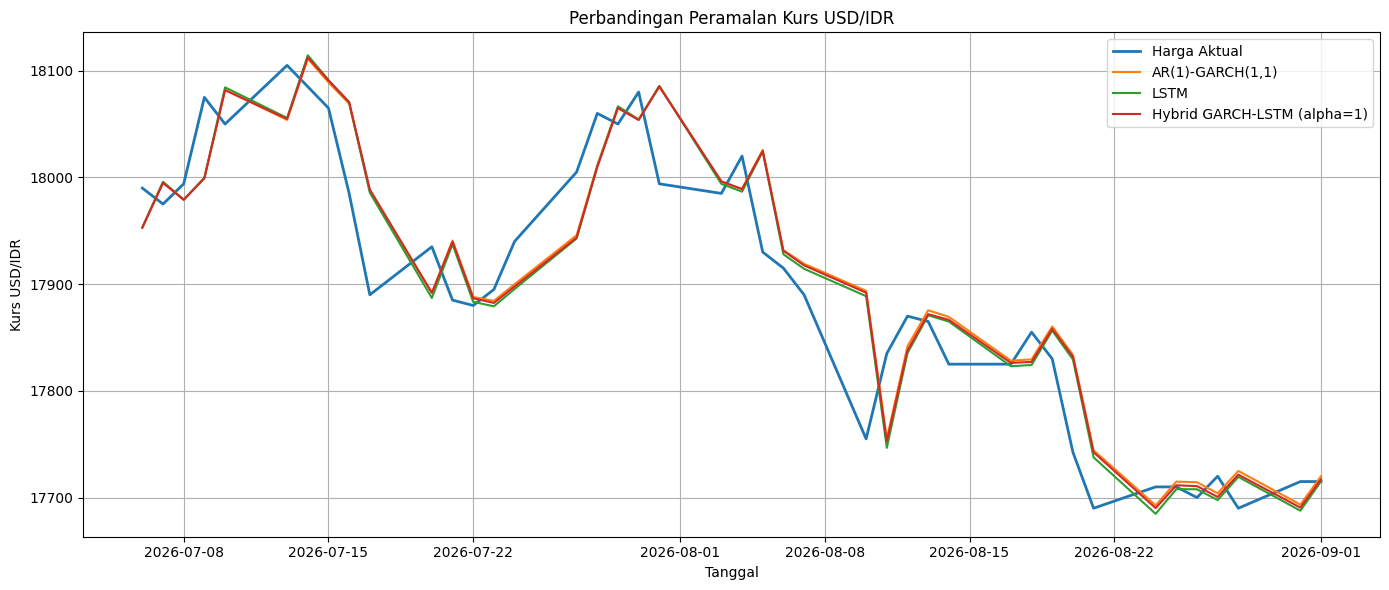

In [48]:
# ==========================================
# GRAFIK PERBANDINGAN ALPHA = 1
# ==========================================

tanggal_test = data.loc[
    return_test.index, "Tanggal"
].to_numpy()

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_test,
    aktual_test,
    label="Harga Aktual",
    linewidth=2
)

plt.plot(
    tanggal_test,
    harga_prediksi_garch,
    label="AR(1)-GARCH(1,1)"
)

plt.plot(
    tanggal_test,
    harga_prediksi_lstm,
    label="LSTM"
)

plt.plot(
    tanggal_test,
    harga_pred_hybrid_a1,
    label="Hybrid GARCH-LSTM (alpha=1)"
)

plt.title("Perbandingan Peramalan Kurs USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## **FORECASTING**

In [49]:
# ==========================================
# LANGKAH 38: PERSIAPAN DATA FINAL
# ==========================================

# Hitung ulang log return dari seluruh harga historis
return_all = (
    100 * np.log(
        data["Terakhir"] / data["Terakhir"].shift(1)
    )
).dropna()

# Pastikan jumlah prediksi GARCH testing sesuai
assert len(pred_return_garch) == len(return_test)

# Residual GARCH OOS pada periode testing yang sebelumnya
resid_test_oos = pd.Series(
    return_test.to_numpy() - pred_return_garch,
    index=return_test.index,
    name="Residual_GARCH_OOS"
)

# Gabungkan residual OOS training dan testing
resid_all_oos = pd.concat([
    resid_train_oos,
    resid_test_oos
]).sort_index()

resid_all_oos = resid_all_oos.dropna()

print("Jumlah data harga historis:", len(data))
print("Jumlah log return historis:", len(return_all))
print("Jumlah residual OOS:", len(resid_all_oos))

print("\nTanggal historis terakhir:")
print(data["Tanggal"].max())

print("\nLima residual terakhir:")
display(resid_all_oos.tail())

Jumlah data harga historis: 1442
Jumlah log return historis: 1441
Jumlah residual OOS: 741

Tanggal historis terakhir:
2026-09-01 00:00:00

Lima residual terakhir:


,Residual_GARCH_OOS
1437,-0.080926
1438,0.090331
1439,-0.197317
1440,0.122152
1441,-0.028574


In [50]:
# ==========================================
# LANGKAH 39: MODEL GARCH FINAL
# ==========================================

model_garch_final = arch_model(
    return_all,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t",
    rescale=False
)

garch_final_fit = model_garch_final.fit(
    disp="off"
)

print(garch_final_fit.summary())

                              AR - GARCH Model Results                              
Dep. Variable:                     Terakhir   R-squared:                       0.002
Mean Model:                              AR   Adj. R-squared:                  0.001
Vol Model:                            GARCH   Log-Likelihood:               -253.267
Distribution:      Standardized Student's t   AIC:                           518.534
Method:                  Maximum Likelihood   BIC:                           550.168
                                              No. Observations:                 1440
Date:                      Wed, Oct 14 2026   Df Residuals:                     1438
Time:                              08:19:23   Df Model:                            2
                                  Mean Model                                  
                  coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------

In [51]:
# ==========================================
# LANGKAH 40: MODEL LSTM RESIDUAL FINAL
# ==========================================

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

lookback = 20

# Normalisasi residual historis
scaler_resid_final = MinMaxScaler()

resid_scaled_final = scaler_resid_final.fit_transform(
    resid_all_oos.to_numpy().reshape(-1, 1)
)

# Membentuk sekuens residual
def buat_sekuens_residual(values, lookback):
    X, y = [], []

    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i, 0])
        y.append(values[i, 0])

    X = np.asarray(X, dtype=np.float32).reshape(
        -1, lookback, 1
    )
    y = np.asarray(y, dtype=np.float32)

    return X, y


X_resid_final, y_resid_final = buat_sekuens_residual(
    resid_scaled_final,
    lookback
)

# Gunakan epoch terbaik dari validasi sebelumnya
if (
    "history_resid" in globals()
    and "val_loss" in history_resid.history
):
    epochs_final = (
        int(np.argmin(history_resid.history["val_loss"])) + 1
    )
else:
    epochs_final = 50

print("Bentuk X:", X_resid_final.shape)
print("Bentuk y:", y_resid_final.shape)
print("Epoch pelatihan final:", epochs_final)

# Model LSTM final
tf.keras.utils.set_random_seed(42)

model_resid_final = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(16),
    Dense(1)
])

model_resid_final.compile(
    optimizer="adam",
    loss="mse"
)

model_resid_final.fit(
    X_resid_final,
    y_resid_final,
    epochs=epochs_final,
    batch_size=32,
    shuffle=False,
    verbose=1
)

print("LSTM residual final selesai dilatih.")

Bentuk X: (721, 20, 1)
Bentuk y: (721,)
Epoch pelatihan final: 100
Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.0570
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0138
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0124
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0122
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0122
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0122
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0122
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0122
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0122
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0121
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0121
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0121
Epoch 13/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0121
Epoch 14/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0121
Ep

In [58]:
# ==========================================
# LANGKAH 41: RAMALAN RETURN HYBRID
# ==========================================

horizon = 30
alpha_final = 1.0

# 1. Ramalan return GARCH untuk 7 langkah ke depan
forecast_garch_future = garch_final_fit.forecast(
    horizon=horizon,
    reindex=False
)

return_garch_future = (
    forecast_garch_future.mean.iloc[-1]
    .to_numpy(dtype=float)
)

# 2. Ramalan residual LSTM secara rekursif
resid_history_scaled = (
    resid_scaled_final.flatten().tolist()
)

resid_lstm_future = []

for h in range(horizon):

    X_input = np.asarray(
        resid_history_scaled[-lookback:],
        dtype=np.float32
    ).reshape(1, lookback, 1)

    pred_scaled = model_resid_final.predict(
        X_input,
        verbose=0
    )

    # Kembalikan ke skala residual asli
    pred_resid = scaler_resid_final.inverse_transform(
        pred_scaled
    )[0, 0]

    resid_lstm_future.append(float(pred_resid))

    # Masukkan residual hasil ramalan untuk langkah berikutnya
    resid_history_scaled.append(
        float(pred_scaled[0, 0])
    )

resid_lstm_future = np.asarray(resid_lstm_future)

# 3. Gabungkan dengan alpha = 1
return_hybrid_future = (
    return_garch_future
    + alpha_final * resid_lstm_future
)

print("Ramalan return GARCH:")
print(np.round(return_garch_future, 6))

print("\nRamalan residual LSTM:")
print(np.round(resid_lstm_future, 6))

print("\nRamalan return hybrid:")
print(np.round(return_hybrid_future, 6))

Ramalan return GARCH:
[0.024298 0.025022 0.025043 0.025044 0.025044 0.025044 0.025044 0.025044
 0.025044 0.025044 0.025044 0.025044 0.025044 0.025044 0.025044 0.025044
 0.025044 0.025044 0.025044 0.025044 0.025044 0.025044 0.025044 0.025044
 0.025044 0.025044 0.025044 0.025044 0.025044 0.025044]

Ramalan residual LSTM:
[-0.001566  0.001841  0.002474  0.003649  0.008653  0.005716  0.004924
  0.005584  0.007414  0.00773   0.007103  0.008508  0.011894  0.013786
  0.013207  0.013468  0.014036  0.013572  0.014856  0.014172  0.014449
  0.014546  0.014627  0.014705  0.014777  0.014819  0.014881  0.014946
  0.015007  0.015056]

Ramalan return hybrid:
[0.022733 0.026863 0.027517 0.028693 0.033697 0.03076  0.029967 0.030628
 0.032458 0.032774 0.032147 0.033552 0.036937 0.03883  0.038251 0.038512
 0.03908  0.038616 0.039899 0.039215 0.039492 0.03959  0.039671 0.039749
 0.03982  0.039863 0.039924 0.03999  0.040051 0.0401  ]


In [59]:
# ==========================================
# LANGKAH 42: KONVERSI RETURN KE HARGA
# ==========================================

last_date = pd.Timestamp(data["Tanggal"].iloc[-1])
last_price = float(data["Terakhir"].iloc[-1])

# Tujuh hari kerja setelah tanggal terakhir data
future_dates = pd.bdate_range(
    start=last_date + pd.Timedelta(days=1),
    periods=horizon
)

# Harga ramalan GARCH
harga_garch_future = []
price_prev_garch = last_price

for r in return_garch_future:
    price_prev_garch *= np.exp(r / 100)
    harga_garch_future.append(price_prev_garch)

# Harga ramalan hybrid
harga_hybrid_future = []
price_prev_hybrid = last_price

for r in return_hybrid_future:
    price_prev_hybrid *= np.exp(r / 100)
    harga_hybrid_future.append(price_prev_hybrid)

# Tabel ramalan akhir
hasil_ramalan_final = pd.DataFrame({
    "Tanggal": future_dates,
    "Return_GARCH": return_garch_future,
    "Residual_LSTM": resid_lstm_future,
    "Return_Hybrid": return_hybrid_future,
    "Harga_Prediksi_GARCH": harga_garch_future,
    "Harga_Prediksi_Hybrid": harga_hybrid_future
})

print("Harga historis terakhir:", last_price)
print("Tanggal historis terakhir:", last_date)

display(hasil_ramalan_final.round(4))

Harga historis terakhir: 17715.0
Tanggal historis terakhir: 2026-09-01 00:00:00


,Tanggal,Return_GARCH,Residual_LSTM,Return_Hybrid,Harga_Prediksi_GARCH,Harga_Prediksi_Hybrid
0,2026-09-02,0.0243,-0.0016,0.0227,17719.3050,17719.0275
1,2026-09-03,0.0250,0.0018,0.0269,17723.7392,17723.7880
2,2026-09-04,0.0250,0.0025,0.0275,17728.1783,17728.6657
3,2026-09-07,0.0250,0.0036,0.0287,17732.6187,17733.7532
4,2026-09-08,0.0250,0.0087,0.0337,17737.0601,17739.7300
5,2026-09-09,0.0250,0.0057,0.0308,17741.5027,17745.1876
6,2026-09-10,0.0250,0.0049,0.0300,17745.9464,17750.5062
7,2026-09-11,0.0250,0.0056,0.0306,17750.3912,17755.9436
8,2026-09-14,0.0250,0.0074,0.0325,17754.8371,17761.7077
9,2026-09-15,0.0250,0.0077,0.0328,17759.2842,17767.5299


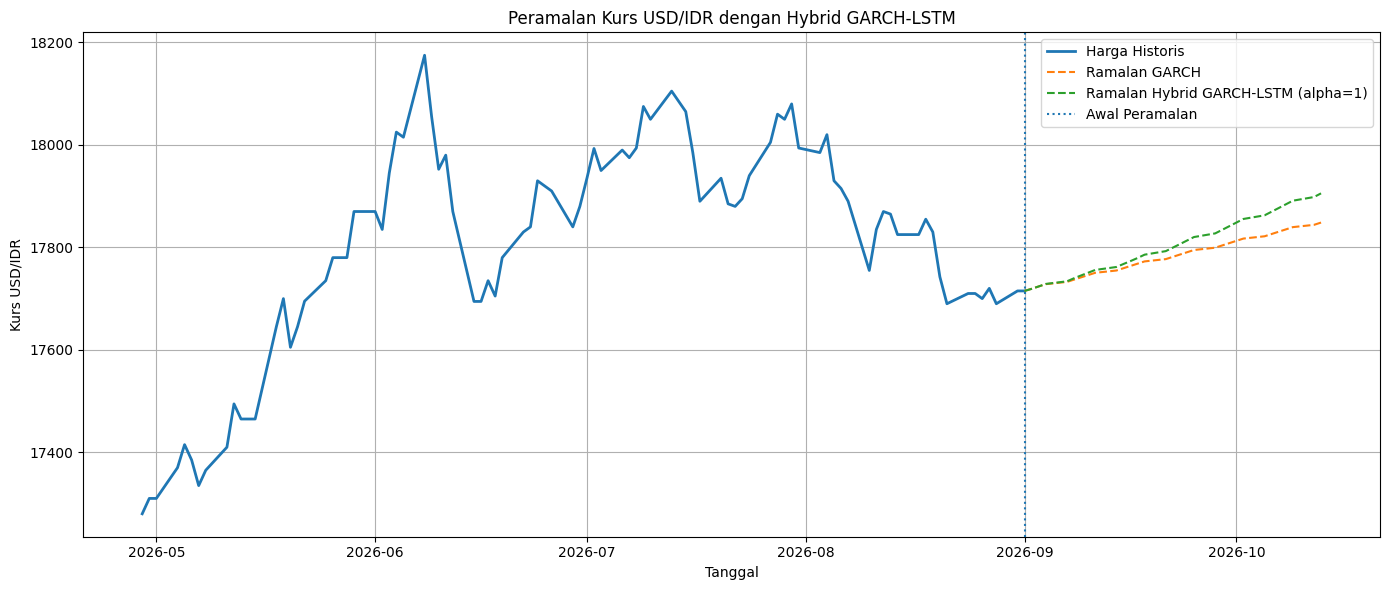

In [62]:
# ==========================================
# LANGKAH 43: VISUALISASI RAMALAN
# ==========================================

n_historis = min(90, len(data))

data_plot = data.tail(n_historis)

tanggal_gabung = [last_date] + list(future_dates)

harga_gabung_garch = (
    [last_price] + list(harga_garch_future)
)

harga_gabung_hybrid = (
    [last_price] + list(harga_hybrid_future)
)

plt.figure(figsize=(14, 6))

plt.plot(
    data_plot["Tanggal"],
    data_plot["Terakhir"],
    label="Harga Historis",
    linewidth=2
)

plt.plot(
    tanggal_gabung,
    harga_gabung_garch,
    linestyle="--",
    label="Ramalan GARCH"
)

plt.plot(
    tanggal_gabung,
    harga_gabung_hybrid,
    linestyle="--",
    label="Ramalan Hybrid GARCH-LSTM (alpha=1)"
)

plt.axvline(
    last_date,
    linestyle=":",
    label="Awal Peramalan"
)

plt.title("Peramalan Kurs USD/IDR dengan Hybrid GARCH-LSTM")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [63]:
# Periksa arah ramalan hybrid
display(
    hasil_ramalan_final[
        [
            "Tanggal",
            "Return_GARCH",
            "Residual_LSTM",
            "Return_Hybrid",
            "Harga_Prediksi_Hybrid"
        ]
    ].round(5)
)

print(
    "Jumlah return hybrid positif:",
    (hasil_ramalan_final["Return_Hybrid"] > 0).sum()
)

print(
    "Jumlah return hybrid negatif:",
    (hasil_ramalan_final["Return_Hybrid"] < 0).sum()
)

,Tanggal,Return_GARCH,Residual_LSTM,Return_Hybrid,Harga_Prediksi_Hybrid
0,2026-09-02,0.02430,-0.00157,0.02273,17719.02754
1,2026-09-03,0.02502,0.00184,0.02686,17723.78798
2,2026-09-04,0.02504,0.00247,0.02752,17728.66565
3,2026-09-07,0.02504,0.00365,0.02869,17733.75321
4,2026-09-08,0.02504,0.00865,0.03370,17739.72997
5,2026-09-09,0.02504,0.00572,0.03076,17745.18759
6,2026-09-10,0.02504,0.00492,0.02997,17750.50617
7,2026-09-11,0.02504,0.00558,0.03063,17755.94364
8,2026-09-14,0.02504,0.00741,0.03246,17761.70773
9,2026-09-15,0.02504,0.00773,0.03277,17767.52987


Jumlah return hybrid positif: 30
Jumlah return hybrid negatif: 0


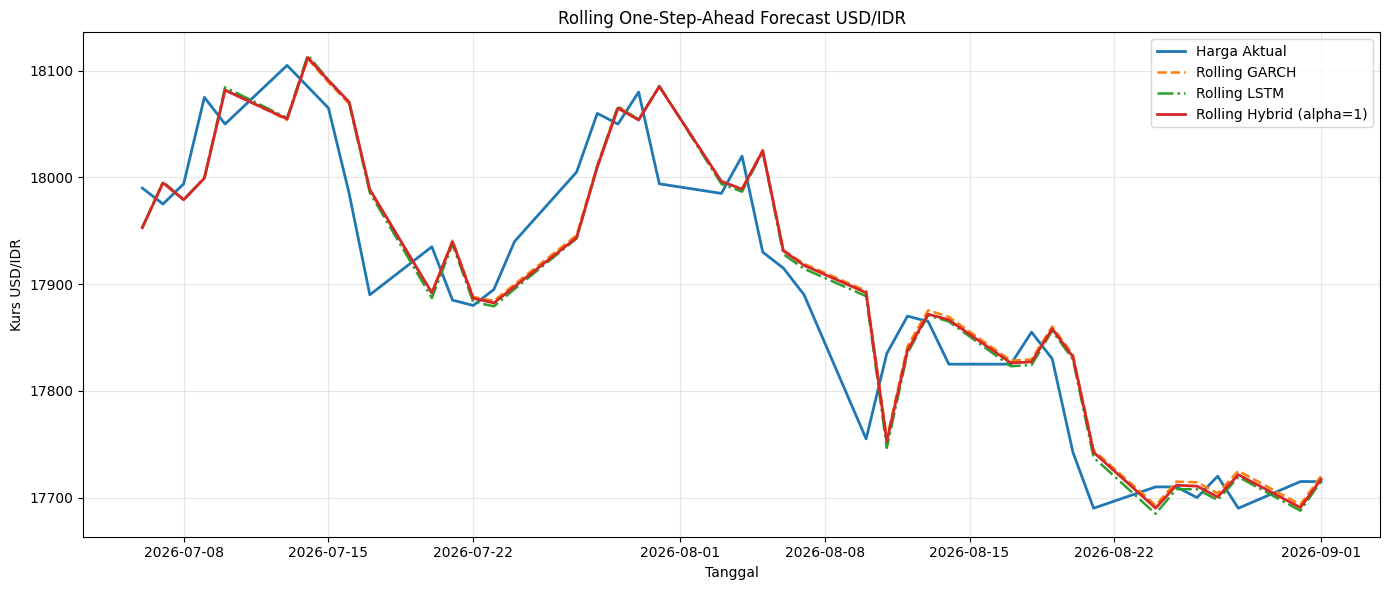

In [64]:
# ==========================================
# ROLLING ONE-STEP-AHEAD: DATA TESTING
# ==========================================

tanggal_test = data.loc[
    return_test.index, "Tanggal"
].to_numpy()

harga_aktual_test = data.loc[
    return_test.index, "Terakhir"
].to_numpy()

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_test,
    harga_aktual_test,
    label="Harga Aktual",
    linewidth=2
)

plt.plot(
    tanggal_test,
    harga_prediksi_garch,
    label="Rolling GARCH",
    linestyle="--",
    linewidth=1.8
)

plt.plot(
    tanggal_test,
    harga_prediksi_lstm,
    label="Rolling LSTM",
    linestyle="-.",
    linewidth=1.8
)

plt.plot(
    tanggal_test,
    harga_pred_hybrid_a1,
    label="Rolling Hybrid (alpha=1)",
    linestyle="-",
    linewidth=2
)

plt.title("Rolling One-Step-Ahead Forecast USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
# ==========================================
# LANGKAH 1: LSTM RESIDUAL DARI TRAINING
# ==========================================

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parameter
n_train = 1400
lookback = 20
alpha_hybrid = 1.0

# Pastikan residual training tersedia
residual_training = pd.Series(
    resid_train_oos
).dropna().astype(float)

# Normalisasi residual training saja
scaler_resid_rolling = MinMaxScaler()

resid_scaled_training = scaler_resid_rolling.fit_transform(
    residual_training.to_numpy().reshape(-1, 1)
)

# Membentuk sekuens residual
X_resid, y_resid = [], []

for j in range(lookback, len(resid_scaled_training)):
    X_resid.append(
        resid_scaled_training[j-lookback:j, 0]
    )
    y_resid.append(
        resid_scaled_training[j, 0]
    )

X_resid = np.asarray(
    X_resid, dtype=np.float32
).reshape(-1, lookback, 1)

y_resid = np.asarray(
    y_resid, dtype=np.float32
)

print("X residual:", X_resid.shape)
print("y residual:", y_resid.shape)

# Gunakan jumlah epoch terbaik dari validasi sebelumnya,
# jika tersedia.
if (
    "history_resid" in globals()
    and "val_loss" in history_resid.history
):
    epochs_final = (
        int(np.argmin(history_resid.history["val_loss"]) + 1)
    )
else:
    epochs_final = 50

# Latih LSTM menggunakan seluruh residual training
tf.keras.utils.set_random_seed(42)

model_resid_rolling = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(16),
    Dense(1)
])

model_resid_rolling.compile(
    optimizer="adam",
    loss="mse"
)

model_resid_rolling.fit(
    X_resid,
    y_resid,
    epochs=epochs_final,
    batch_size=32,
    shuffle=False,
    verbose=1
)

print("LSTM residual training selesai.")

X residual: (679, 20, 1)
y residual: (679,)
Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0599
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0142
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0126
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0124
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0124
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0124
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0124
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0124
Epoch 9/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0124
Epoch 10/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0123
Epoch 11/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0123
Epoch 12/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0123
Epoch 13/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0123
Epoch 14/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0123
Epoch 15/100
22/22 

In [66]:
# ==========================================
# LANGKAH 2: ROLLING ONE-STEP-AHEAD FORECAST
# HYBRID GARCH-LSTM (ALPHA = 1)
# ==========================================

from arch import arch_model
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# ------------------------------------------
# 1. DATA HISTORIS
# ------------------------------------------

harga_historis = data["Terakhir"].astype(float).reset_index(drop=True)
tanggal_historis = pd.to_datetime(
    data["Tanggal"]
).reset_index(drop=True)

# Log return dalam persen
return_historis = (
    100 * np.log(
        harga_historis / harga_historis.shift(1)
    )
)

# Mulai dari observasi testing
start = n_train

# Riwayat residual yang tersedia pada akhir training
resid_history_scaled = (
    resid_scaled_training.flatten().tolist()
)

# Menampung hasil ramalan
forecast_return_garch = []
forecast_return_residual = []
forecast_return_hybrid = []

forecast_level_garch = []
forecast_level_hybrid = []

# ------------------------------------------
# 2. ROLLING FORECAST
# ------------------------------------------

for i in range(start, len(harga_historis)):

    # Return yang tersedia sebelum observasi ke-i
    data_roll = return_historis.iloc[1:i].dropna()

    # --------------------------------------
    # FIT AR(1)-GARCH(1,1)
    # --------------------------------------

    model_roll = arch_model(
        data_roll,
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="t",
        rescale=False
    )

    hasil_roll = model_roll.fit(
        disp="off",
        show_warning=False
    )

    # Ramalan return GARCH satu langkah
    forecast_roll = hasil_roll.forecast(
        horizon=1,
        reindex=False
    )

    pred_return_garch = float(
        forecast_roll.mean.iloc[-1, 0]
    )

    # --------------------------------------
    # PREDIKSI RESIDUAL DENGAN LSTM
    # --------------------------------------

    X_input = np.asarray(
        resid_history_scaled[-lookback:],
        dtype=np.float32
    ).reshape(1, lookback, 1)

    pred_resid_scaled = model_resid_rolling.predict(
        X_input,
        verbose=0
    )

    pred_resid = float(
        scaler_resid_rolling.inverse_transform(
            pred_resid_scaled
        )[0, 0]
    )

    # --------------------------------------
    # GABUNGKAN GARCH DAN LSTM
    # --------------------------------------

    pred_return_hybrid = (
        pred_return_garch
        + alpha_hybrid * pred_resid
    )

    # --------------------------------------
    # KONVERSI RETURN MENJADI HARGA
    # --------------------------------------

    # Harga aktual periode sebelumnya sudah tersedia
    previous_actual = float(
        harga_historis.iloc[i - 1]
    )

    pred_price_garch = (
        previous_actual
        * np.exp(pred_return_garch / 100)
    )

    pred_price_hybrid = (
        previous_actual
        * np.exp(pred_return_hybrid / 100)
    )

    # --------------------------------------
    # SIMPAN HASIL PREDIKSI
    # --------------------------------------

    forecast_return_garch.append(pred_return_garch)
    forecast_return_residual.append(pred_resid)
    forecast_return_hybrid.append(pred_return_hybrid)

    forecast_level_garch.append(pred_price_garch)
    forecast_level_hybrid.append(pred_price_hybrid)

    # --------------------------------------
    # UPDATE RESIDUAL SETELAH AKTUAL TERSEDIA
    # --------------------------------------

    actual_return = float(return_historis.iloc[i])

    # Residual OOS dihitung dari prediksi GARCH
    actual_resid = actual_return - pred_return_garch

    actual_resid_scaled = scaler_resid_rolling.transform(
        np.array([[actual_resid]])
    )[0, 0]

    resid_history_scaled.append(
        float(actual_resid_scaled)
    )

print("Rolling forecast selesai.")
print("Jumlah ramalan:", len(forecast_level_hybrid))

Rolling forecast selesai.
Jumlah ramalan: 42


In [67]:
# ==========================================
# LANGKAH 3: TABEL HASIL ROLLING FORECAST
# ==========================================

hasil_rolling_historis = pd.DataFrame({
    "Tanggal": tanggal_historis.iloc[start:].to_numpy(),
    "Harga_Aktual": harga_historis.iloc[start:].to_numpy(),
    "Return_GARCH": forecast_return_garch,
    "Residual_Prediksi_LSTM": forecast_return_residual,
    "Return_Hybrid": forecast_return_hybrid,
    "Prediksi_Harga_GARCH": forecast_level_garch,
    "Prediksi_Harga_Hybrid": forecast_level_hybrid
})

display(hasil_rolling_historis.head(10).round(5))

,Tanggal,Harga_Aktual,Return_GARCH,Residual_Prediksi_LSTM,Return_Hybrid,Prediksi_Harga_GARCH,Prediksi_Harga_Hybrid
0,2026-07-06,17990.0,0.01789,0.03061,0.04850,17953.21108,17958.70760
1,2026-07-07,17975.0,0.03223,0.01940,0.05163,17995.79975,17999.29110
2,2026-07-08,17994.0,0.02290,0.03167,0.05458,17979.11732,17984.81256
3,2026-07-09,18075.0,0.02865,0.03336,0.06201,17999.15613,18005.16167
4,2026-07-10,18050.0,0.03928,0.02258,0.06186,18082.10141,18086.18463
5,2026-07-13,18105.0,0.02156,0.03953,0.06108,18053.89139,18061.02874
6,2026-07-14,18085.0,0.03453,0.03781,0.07235,18111.25339,18118.10330
7,2026-07-15,18065.0,0.02260,0.04747,0.07007,18089.08796,18097.67694
8,2026-07-16,17985.0,0.02243,0.05004,0.07247,18069.05325,18078.09637
9,2026-07-17,17890.0,0.01237,0.06090,0.07327,17987.22550,17998.18296


In [68]:
# ==========================================
# LANGKAH 4: EVALUASI ROLLING FORECAST
# ==========================================

aktual = hasil_rolling_historis["Harga_Aktual"].to_numpy()

def hitung_metrik_rolling(nama, aktual, prediksi):
    return {
        "Model": nama,
        "RMSE": np.sqrt(
            mean_squared_error(aktual, prediksi)
        ),
        "MAE": mean_absolute_error(
            aktual, prediksi
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            aktual, prediksi
        ) * 100
    }

hasil_evaluasi_rolling = pd.DataFrame([
    hitung_metrik_rolling(
        "Rolling AR(1)-GARCH(1,1)",
        aktual,
        hasil_rolling_historis["Prediksi_Harga_GARCH"]
    ),
    hitung_metrik_rolling(
        "Rolling Hybrid GARCH-LSTM (alpha=1)",
        aktual,
        hasil_rolling_historis["Prediksi_Harga_Hybrid"]
    )
])

display(
    hasil_evaluasi_rolling.round(5)
)

,Model,RMSE,MAE,MAPE (%)
0,"Rolling AR(1)-GARCH(1,1)",50.31160,39.67248,0.22159
1,Rolling Hybrid GARCH-LSTM (alpha=1),51.94715,40.72433,0.22750


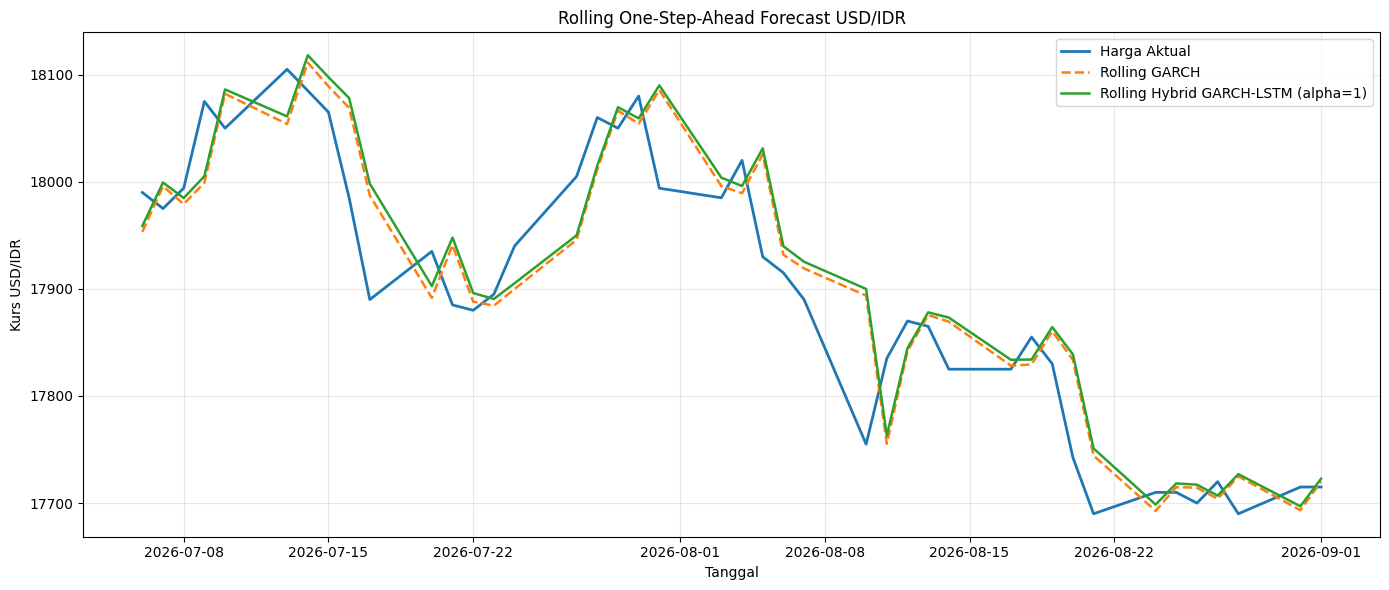

In [69]:
# ==========================================
# LANGKAH 5: VISUALISASI
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    hasil_rolling_historis["Tanggal"],
    hasil_rolling_historis["Harga_Aktual"],
    label="Harga Aktual",
    linewidth=2
)

plt.plot(
    hasil_rolling_historis["Tanggal"],
    hasil_rolling_historis["Prediksi_Harga_GARCH"],
    label="Rolling GARCH",
    linestyle="--",
    linewidth=1.8
)

plt.plot(
    hasil_rolling_historis["Tanggal"],
    hasil_rolling_historis["Prediksi_Harga_Hybrid"],
    label="Rolling Hybrid GARCH-LSTM (alpha=1)",
    linewidth=1.8
)

plt.title("Rolling One-Step-Ahead Forecast USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Jumlah data harga: 1442
Jumlah data training: 1400
Jumlah data testing: 42
Jumlah residual training: 699
Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0599
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0142
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0126
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0124
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0124
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0124
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0124
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0124
Epoch 9/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0124
Epoch 10/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0123
Epoch 11/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0123
Epoch 12/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0123
Epoch 13/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0123
Epoch 14/100
22/22 ━━━━━━━━━

,Tanggal,Harga_Aktual,Return_GARCH,Residual_Prediksi_LSTM,Return_Hybrid,Prediksi_Harga_GARCH,Prediksi_Harga_Hybrid
0,2026-07-06,17990.0,0.01789,0.03061,0.04850,17953.21108,17958.70760
1,2026-07-07,17975.0,0.03223,0.01940,0.05163,17995.79975,17999.29110
2,2026-07-08,17994.0,0.02290,0.03167,0.05458,17979.11732,17984.81256
3,2026-07-09,18075.0,0.02865,0.03336,0.06201,17999.15613,18005.16167
4,2026-07-10,18050.0,0.03928,0.02258,0.06186,18082.10141,18086.18463
5,2026-07-13,18105.0,0.02156,0.03953,0.06108,18053.89139,18061.02874
6,2026-07-14,18085.0,0.03453,0.03781,0.07235,18111.25339,18118.10330
7,2026-07-15,18065.0,0.02260,0.04747,0.07007,18089.08796,18097.67694
8,2026-07-16,17985.0,0.02243,0.05004,0.07247,18069.05325,18078.09637
9,2026-07-17,17890.0,0.01237,0.06090,0.07327,17987.22550,17998.18296


,Model,RMSE,MAE,MAPE (%)
0,"AR(1)-GARCH(1,1)",50.31160,39.67248,0.22159
1,Hybrid GARCH-LSTM (alpha=1),51.94715,40.72433,0.22750


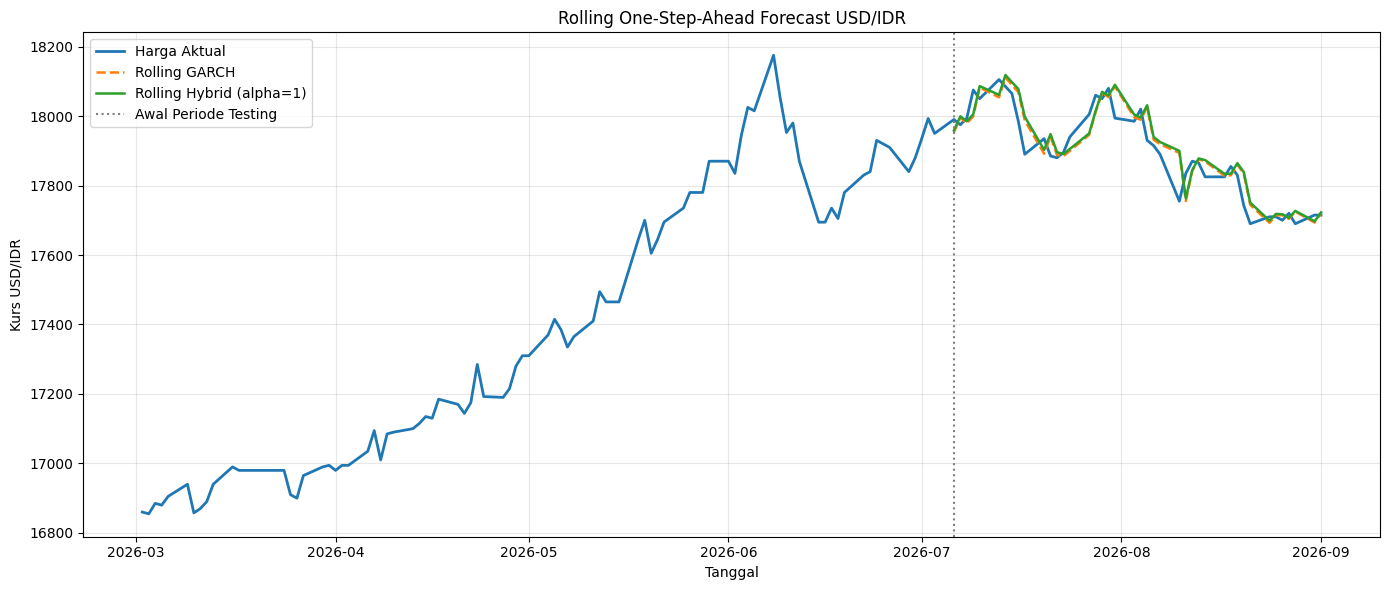

In [70]:
# ==========================================
# ROLLING ONE-STEP-AHEAD FORECAST
# HYBRID GARCH-LSTM (ALPHA = 1)
# DATA HISTORIS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from arch import arch_model
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

# ==========================================
# 1. PERSIAPAN DATA
# ==========================================

harga = data["Terakhir"].astype(float).reset_index(drop=True)
tanggal = pd.to_datetime(data["Tanggal"]).reset_index(drop=True)

# Log return dalam persen
return_historis = (
    100 * np.log(harga / harga.shift(1))
)

n_train = 1400
lookback = 20
alpha = 1.0

# Pastikan residual GARCH training tersedia
residual_train = (
    pd.Series(resid_train_oos)
    .dropna()
    .astype(float)
    .reset_index(drop=True)
)

print("Jumlah data harga:", len(harga))
print("Jumlah data training:", n_train)
print("Jumlah data testing:", len(harga) - n_train)
print("Jumlah residual training:", len(residual_train))

# ==========================================
# 2. PERSIAPAN SEKUENS LSTM RESIDUAL
# ==========================================

scaler_hist = MinMaxScaler()

residual_scaled = scaler_hist.fit_transform(
    residual_train.to_numpy().reshape(-1, 1)
)

X_resid, y_resid = [], []

for j in range(lookback, len(residual_scaled)):
    X_resid.append(
        residual_scaled[j-lookback:j, 0]
    )
    y_resid.append(
        residual_scaled[j, 0]
    )

X_resid = np.asarray(
    X_resid, dtype=np.float32
).reshape(-1, lookback, 1)

y_resid = np.asarray(y_resid, dtype=np.float32)

# Gunakan epoch terbaik dari validasi training sebelumnya
if (
    "history_resid" in globals()
    and "val_loss" in history_resid.history
):
    epochs_final = (
        int(np.argmin(history_resid.history["val_loss"])) + 1
    )
else:
    epochs_final = 50

tf.keras.utils.set_random_seed(42)

model_lstm_hist = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(16),
    Dense(1)
])

model_lstm_hist.compile(
    optimizer="adam",
    loss="mse"
)

model_lstm_hist.fit(
    X_resid,
    y_resid,
    epochs=epochs_final,
    batch_size=32,
    shuffle=False,
    verbose=1
)

print("Model LSTM residual selesai dilatih.")

# ==========================================
# 3. ROLLING ONE-STEP-AHEAD FORECAST
# ==========================================

pred_return_garch_hist = []
pred_residual_lstm_hist = []
pred_return_hybrid_hist = []

pred_harga_garch_hist = []
pred_harga_hybrid_hist = []

# Riwayat residual yang sudah tersedia sampai akhir training
riwayat_residual_scaled = residual_scaled.flatten().tolist()

for i in range(n_train, len(harga)):

    # --------------------------------------
    # A. DATA RETURN YANG TERSEDIA
    # --------------------------------------

    # Hanya return sampai periode sebelum i
    data_roll = return_historis.iloc[1:i].dropna()

    # --------------------------------------
    # B. FIT AR(1)-GARCH(1,1)
    # --------------------------------------

    model_roll = arch_model(
        data_roll,
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="t",
        rescale=False
    )

    fit_roll = model_roll.fit(
        disp="off",
        show_warning=False
    )

    forecast_roll = fit_roll.forecast(
        horizon=1,
        reindex=False
    )

    pred_r_garch = float(
        forecast_roll.mean.iloc[-1, 0]
    )

    # --------------------------------------
    # C. PREDIKSI RESIDUAL LSTM
    # --------------------------------------

    X_input = np.asarray(
        riwayat_residual_scaled[-lookback:],
        dtype=np.float32
    ).reshape(1, lookback, 1)

    pred_scaled = model_lstm_hist.predict(
        X_input,
        verbose=0
    )

    pred_resid = float(
        scaler_hist.inverse_transform(
            pred_scaled
        )[0, 0]
    )

    # --------------------------------------
    # D. HYBRID DENGAN ALPHA = 1
    # --------------------------------------

    pred_r_hybrid = (
        pred_r_garch + alpha * pred_resid
    )

    # --------------------------------------
    # E. KONVERSI RETURN MENJADI HARGA
    # --------------------------------------

    harga_sebelumnya = float(harga.iloc[i - 1])

    pred_p_garch = (
        harga_sebelumnya * np.exp(pred_r_garch / 100)
    )

    pred_p_hybrid = (
        harga_sebelumnya * np.exp(pred_r_hybrid / 100)
    )

    # --------------------------------------
    # F. SIMPAN HASIL PREDIKSI
    # --------------------------------------

    pred_return_garch_hist.append(pred_r_garch)
    pred_residual_lstm_hist.append(pred_resid)
    pred_return_hybrid_hist.append(pred_r_hybrid)

    pred_harga_garch_hist.append(pred_p_garch)
    pred_harga_hybrid_hist.append(pred_p_hybrid)

    # --------------------------------------
    # G. UPDATE SETELAH AKTUAL TERSEDIA
    # --------------------------------------

    # Aktual periode i baru digunakan setelah ramalan dibuat
    return_aktual = float(return_historis.iloc[i])

    # Residual aktual berdasarkan ramalan GARCH periode i
    residual_aktual = return_aktual - pred_r_garch

    residual_aktual_scaled = scaler_hist.transform(
        np.array([[residual_aktual]])
    )[0, 0]

    riwayat_residual_scaled.append(
        float(residual_aktual_scaled)
    )

print("Rolling forecast selesai.")
print("Jumlah hasil ramalan:", len(pred_harga_hybrid_hist))

# ==========================================
# 4. TABEL HASIL FORECASTING HISTORIS
# ==========================================

hasil_rolling_historis = pd.DataFrame({
    "Tanggal": tanggal.iloc[n_train:].to_numpy(),
    "Harga_Aktual": harga.iloc[n_train:].to_numpy(),
    "Return_GARCH": pred_return_garch_hist,
    "Residual_Prediksi_LSTM": pred_residual_lstm_hist,
    "Return_Hybrid": pred_return_hybrid_hist,
    "Prediksi_Harga_GARCH": pred_harga_garch_hist,
    "Prediksi_Harga_Hybrid": pred_harga_hybrid_hist
})

display(hasil_rolling_historis.round(5))

# ==========================================
# 5. EVALUASI MODEL
# ==========================================

aktual = hasil_rolling_historis["Harga_Aktual"].to_numpy()

def evaluasi_rolling(nama, aktual, prediksi):
    return {
        "Model": nama,
        "RMSE": np.sqrt(
            mean_squared_error(aktual, prediksi)
        ),
        "MAE": mean_absolute_error(
            aktual, prediksi
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            aktual, prediksi
        ) * 100
    }

hasil_evaluasi_historis = pd.DataFrame([
    evaluasi_rolling(
        "AR(1)-GARCH(1,1)",
        aktual,
        pred_harga_garch_hist
    ),
    evaluasi_rolling(
        "Hybrid GARCH-LSTM (alpha=1)",
        aktual,
        pred_harga_hybrid_hist
    )
])

display(hasil_evaluasi_historis.round(5))

# ==========================================
# 6. GRAFIK FORECASTING HISTORIS
# ==========================================

# Tampilkan konteks historis sebelum periode testing
awal_plot = max(0, n_train - 90)

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal.iloc[awal_plot:],
    harga.iloc[awal_plot:],
    label="Harga Aktual",
    linewidth=2
)

plt.plot(
    hasil_rolling_historis["Tanggal"],
    hasil_rolling_historis["Prediksi_Harga_GARCH"],
    linestyle="--",
    linewidth=1.8,
    label="Rolling GARCH"
)

plt.plot(
    hasil_rolling_historis["Tanggal"],
    hasil_rolling_historis["Prediksi_Harga_Hybrid"],
    linestyle="-",
    linewidth=1.8,
    label="Rolling Hybrid (alpha=1)"
)

plt.axvline(
    tanggal.iloc[n_train],
    linestyle=":",
    color="gray",
    label="Awal Periode Testing"
)

plt.title("Rolling One-Step-Ahead Forecast USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Kurs USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()